# COURSE: Deep Learning for Music Technology
## SECTION: Transformers for music
### EXERCISE E2: Your first music GPT (jazz edition)
#### Builds on: `DUDL_RNN_loremipsum` (same character tables, same loss, same optimizer)

**Goal.** Train a small transformer (a "mini-GPT") from scratch on **jazz solos written as text**, and *hear* it learn.

In `DUDL_RNN_loremipsum` an LSTM learned to write fake Latin one character at a time. Here we keep the same idea (characters → numbers → predict the next character) but:

* the text is **music**: jazz solos in [ABC notation](https://abcnotation.com/wiki/abc:standard:v2.1), with the chord changes;
* the `nn.LSTM` is replaced by **self-attention**: the model looks back at all previous characters at once and learns *which ones matter*.

| Part | What you do | Time |
|---|---|---|
| 1 | Load the data, read jazz ABC, build `letter2number` | 15 min |
| 2 | Read the model, count its parameters | 15 min |
| 3 | Train it (GPU) and watch the loss | 15–20 min |
| 4 | **The learning curve you can hear**: listen to 3 checkpoints | 30 min |
| 5 | Sampling: temperature, top-k, a solo over real chord changes, your own prompt | 40 min |
| 6 | Look inside: attention maps | 20 min |
| ★ | Code challenges (optional) | — |
| H2 | Home: sampling lab | 1.5 h |

**Before you start (Colab):** *Runtime → Change runtime type → T4 GPU*. Then run the cells from top to bottom.
Cells marked **Helper** are folded: run them, you don't need to read them (but you may!).
Look for **❓ Questions**: answer them in your notes, they are part of the exercise.

### The data: the Weimar Jazz Database

The [Weimar Jazz Database](https://jazzomat.hfm-weimar.de/dbformat/dboverview.html) (Jazzomat Research Project, HfM Weimar) contains **456 jazz solos by 78 players** (Charlie Parker, John Coltrane, Sonny Rollins, Miles Davis, Chet Baker, Michael Brecker…), transcribed note by note, with the chord changes and the form.

We take the 431 solos in 4/4 and turn **every chorus** (one time through the form of the tune: a 12-bar blues, a 32-bar AABA song…) into one ABC tune. That gives about **1,250 choruses, 860,000 characters**: as much text as a 300-page novel. Not much for a model that starts from zero, so we also **play every solo in all 12 keys** (*data augmentation*, like flipping images): **15,000 choruses, 11.7 million characters**.

**There is no ready-made jazz dataset in ABC notation**, so the helper cell below writes it: it reads the solos from the database, rounds the rhythm to 16th notes or 8th-note triplets, writes swing 8ths straight (like on a lead sheet), and adds the chord symbols.

**Licence and ethics.** The database is free to use under the [Open Database License (ODbL)](https://opendatacommons.org/licenses/odbl/1.0/): you must credit it and share changed versions under the same licence. Three things to think about:
1. These are real improvisations by real musicians, many of them still alive.
2. A transcription is already an interpretation, and so is our conversion: we rounded the rhythm and dropped dynamics and pitch bends.
3. The player's name is part of the data (`C:` line). What does it mean to ask a model for "a solo by Charlie Parker"?

# Setup

In [1]:
### import libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import math, os, re, time, random, urllib.request

# for data visualization
import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')
from IPython.display import clear_output

In [2]:
# use the GPU if there is one (Colab: Runtime > Change runtime type > T4 GPU)
device = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
print(device)

mps


In [3]:
#@title Where to save your work
# Colab can disconnect at any time. Checkpoints saved to Google Drive survive that.
USE_DRIVE = True  #@param {type:"boolean"}

try:
  import google.colab
  IN_COLAB = True
except ImportError:
  IN_COLAB = False

if IN_COLAB and USE_DRIVE:
  from google.colab import drive
  drive.mount('/content/drive')
  SAVE_DIR = '/content/drive/MyDrive/music_transformers/E2'
else:
  SAVE_DIR = 'E2_files'
os.makedirs(SAVE_DIR, exist_ok=True)
print('Files will be saved in', SAVE_DIR)

Files will be saved in E2_files


In [4]:
#@title Helper 1: Weimar Jazz Database → ABC (run me, no need to read)
# Teacher-side data preparation. One ABC tune per chorus; rhythm rounded per beat to a
# 16th-note grid or an 8th-triplet grid; swing 8ths written straight; Jazzomat chord
# names (C-7, Fj7, Bb79b) rewritten as lead-sheet chords (Cm7, Fmaj7, Bb7b9); the chord is
# repeated in every bar; every flat/sharp is written on its note; optional transposition.
import re, sqlite3, unicodedata
import numpy as np
import pandas as pd

TPB = 12                      # ticks per beat (quarter): LCM of 4 (16ths) and 3 (triplets)
BAR = 4 * TPB                 # 4/4 only
LEGATO_GAP = 12              # gaps shorter than this (a quarter) are closed: notes are held until the next one
EXPLICIT_ACCIDENTALS = True  # every flat/sharp is written on the note (_B even in K:Bb): the model
                             # can read each pitch without remembering the key signature
CHORD_EVERY_BAR = True       # repeat the current chord at the start of every bar: the model always
                             # sees the harmony, even when a chord lasts for many bars

# ---------------------------------------------------------------- keys & spelling
LETTERS = 'CDEFGAB'
NAT_PC = dict(C=0, D=2, E=4, F=5, G=7, A=9, B=11)
SHARP_ORDER, FLAT_ORDER = 'FCGDAEB', 'BEADGCF'
MAJOR_FIFTHS = {'C': 0, 'G': 1, 'D': 2, 'A': 3, 'E': 4, 'B': 5, 'F#': 6, 'C#': 7,
                'F': -1, 'Bb': -2, 'Eb': -3, 'Ab': -4, 'Db': -5, 'Gb': -6, 'Cb': -7}
PC_NAME = {0: 'C', 1: 'Db', 2: 'D', 3: 'Eb', 4: 'E', 5: 'F', 6: 'Gb', 7: 'G', 8: 'Ab',
           9: 'A', 10: 'Bb', 11: 'B'}
MINOR_TONIC = {0: 'C', 1: 'C#', 2: 'D', 3: 'Eb', 4: 'E', 5: 'F', 6: 'F#', 7: 'G',
               8: 'G#', 9: 'A', 10: 'Bb', 11: 'B'}


def name_to_pc(n):
    pc = NAT_PC[n[0]]
    for a in n[1:]:
        pc += {'#': 1, 'b': -1}[a]
    return pc % 12


def parse_key(k, shift=0):
    """'Bb-maj' -> ('Bb', fifths); unknown / chromatic -> ('C', 0). shift: semitones up."""
    if not k or '-' not in k:
        k = (k or '') + '-maj'
    tonic, mode = k.split('-', 1)
    if not re.fullmatch(r'[A-G][#b]?', tonic) or mode == 'chrom':
        tonic, mode = 'C', 'maj'
    pc = (name_to_pc(tonic) + shift) % 12
    if mode == 'min':
        name = MINOR_TONIC[pc]
        return name + 'm', MAJOR_FIFTHS[PC_NAME[(pc + 3) % 12]]
    if mode == 'dor':
        return PC_NAME[pc] + 'dor', MAJOR_FIFTHS[PC_NAME[(pc - 2) % 12]]
    if mode == 'mix':
        return PC_NAME[pc] + 'mix', MAJOR_FIFTHS[PC_NAME[(pc + 5) % 12]]
    return PC_NAME[pc], MAJOR_FIFTHS[PC_NAME[pc]]   # maj, blues, ...


def transpose_note_name(n, shift, letter_shift, flats=True):
    """Transpose a note name ('F#', 'Bb') keeping the spelling of the interval when possible."""
    pc = (name_to_pc(n) + shift) % 12
    letter = LETTERS[(LETTERS.index(n[0]) + letter_shift) % 7]
    acc = (pc - NAT_PC[letter] + 6) % 12 - 6
    name = letter + {-1: 'b', 0: '', 1: '#'}[acc] if acc in (-1, 0, 1) else None
    if name in (None, 'Cb', 'Fb', 'E#', 'B#'):       # rare on lead sheets
        name = PC_NAME[pc] if flats else {1: 'C#', 3: 'D#', 6: 'F#', 8: 'G#', 10: 'A#'}.get(pc, PC_NAME[pc])
    return name


def transpose_chord(c, shift, letter_shift, flats=True):
    """Transpose a Jazzomat chord ('F#-7', 'Bb79b/D')."""
    if not shift or c in ('NC', ''):
        return c
    m = re.fullmatch(r'([A-G][#b]?)(.*?)(?:/([A-G][#b]?))?', c)
    if not m:
        return c
    root, q, bass = m.groups()
    out = transpose_note_name(root, shift, letter_shift, flats) + q
    if bass:
        out += '/' + transpose_note_name(bass, shift, letter_shift, flats)
    return out


def key_signature(fifths):
    sig = {l: 0 for l in LETTERS}
    if fifths > 0:
        for l in SHARP_ORDER[:fifths]:
            sig[l] = 1
    else:
        for l in FLAT_ORDER[:-fifths]:
            sig[l] = -1
    return sig


def spelling_table(key_name, fifths):
    """pitch class -> (letter, accidental) for this key."""
    sig = key_signature(fifths)
    lead = None
    if key_name.endswith('m') and not key_name.endswith('dor'):
        tonic = key_name[:-1]
        lead = ((name_to_pc(tonic) - 1) % 12, LETTERS[(LETTERS.index(tonic[0]) - 1) % 7])
    table = {}
    for pc in range(12):
        best = None
        for l in LETTERS:
            for acc in (-1, 0, 1):
                if (NAT_PC[l] + acc) % 12 != pc:
                    continue
                if acc == sig[l]:
                    score = 0
                elif lead and pc == lead[0] and l == lead[1]:
                    score = 0.5
                elif acc == 0:
                    score = 1
                elif l + str(acc) in ('C-1', 'F-1', 'E1', 'B1'):
                    score = 5
                else:
                    score = 2 if acc == -1 else 3      # jazz: prefer flats
                if best is None or score < best[0]:
                    best = (score, l, acc)
        table[pc] = best[1:]
    return table, sig


def abc_pitch(midi, table):
    letter, acc = table[midi % 12]
    octave = (midi - acc) // 12 - 1          # MIDI 60 = C4
    s = letter if octave <= 4 else letter.lower()
    if octave > 5:
        s += "'" * (octave - 5)
    if octave < 4:
        s += ',' * (4 - octave)
    return letter, acc, s


# ---------------------------------------------------------------- chords
TENSION = {'9b': 'b9', '9': '9', '9#': '#9', '11': '11', '11#': '#11', '13': '13', '13b': 'b13'}


def chord_name(c):
    """Jazzomat chord syntax -> common lead-sheet syntax (Cm7, Fmaj7, Bb7b9, ...)."""
    if c in ('NC', ''):
        return 'N.C.' if c else ''
    m = re.fullmatch(r'([A-G][#b]?)(.*?)(?:/([A-G][#b]?))?', c)
    if not m:
        return c
    root, q, bass = m.groups()
    out = None
    alt = q.endswith('alt')
    if alt:
        q = q[:-3]
    if q.startswith('m7b5'):
        out, rest = 'm7b5', q[4:]
    elif q.startswith('o7'):
        out, rest = 'dim7', q[2:]
    elif q.startswith('o'):
        out, rest = 'dim', q[1:]
    else:
        tri = ''
        if q.startswith('-'):
            tri, q = 'm', q[1:]
        elif q.startswith('+'):
            tri, q = '+', q[1:]
        elif q.startswith('sus'):
            tri, q = 'sus', q[3:]
        sev = ''
        for s in ('j7', '7', '69', '6'):
            if q.startswith(s):
                sev, q = s, q[len(s):]
                break
        tens = re.findall(r'(9b|9#|9|11#|11|13b|13)', q)
        tens = [TENSION[t] for t in tens]
        if tri == 'sus':
            base = {'': 'sus4', '7': '7sus4'}.get(sev, sev + 'sus4')
            if sev == '7' and '13' in tens:
                base = '13sus4'
            elif sev == '7' and '9' in tens:
                base = '9sus4'
            out = base
        elif tri == '+':
            out = 'aug' if sev == '' else '7#5'
        else:
            if sev == 'j7':
                sev = 'maj7'
            if sev in ('7', 'maj7') and tens:
                # 9 / 13 upgrade the chord name, altered tensions are appended
                plain = [t for t in tens if t in ('9', '11', '13')]
                altered = [t for t in tens if t not in plain]
                top = plain[-1] if plain else None
                if top:
                    sev = sev.replace('7', top) if not (top == '11' and tri == '') else sev + '#11'
                sev += ''.join(altered)
            elif sev == '' and tens:
                sev = 'add9' if '9' in tens else ''
            out = tri + sev
    if alt:
        out = out.replace('7', '7alt', 1) if '7' in out else out + '7alt'
    name = root + out
    if bass:
        name += '/' + bass
    return name


# ---------------------------------------------------------------- quantisation
def quantise_solo(mel, beats):
    """Return a monophonic list of [on_tick, off_tick, midi]; tick 0 = first bar of the solo."""
    bar0 = min(mel.bar.min(), beats.bar.min())
    gidx_beats = (beats.bar - bar0) * 4 + (beats.beat - 1)
    bt, bi = beats.onset.values, gidx_beats.values.astype(float)
    order = np.argsort(bt)
    bt, bi = bt[order], bi[order]
    last_dur = np.median(np.diff(bt[-9:])) if len(bt) > 2 else 0.5

    def time_to_beat(t):
        if t <= bt[-1]:
            return float(np.interp(t, bt, bi))
        return bi[-1] + (t - bt[-1]) / last_dur

    g = (mel.bar.values - bar0) * 4 + (mel.beat.values - 1)
    frac = (mel.tatum.values - 1) / mel.division.values
    on = g + frac
    off = np.array([time_to_beat(t) for t in (mel.onset + mel.duration).values])
    off = np.maximum(off, on + 0.05)
    pitch = mel.pitch.round().astype(int).values

    # choose the grid of every beat from the onsets that fall in it
    nbeats = int(np.ceil(max(off.max(), on.max()))) + 2
    errs = np.zeros((nbeats, 2))
    for o in on:
        b, f = int(np.floor(o)), o - np.floor(o)
        errs[b, 0] += abs(f * 4 - round(f * 4)) / 4
        errs[b, 1] += abs(f * 3 - round(f * 3)) / 3
    triplet = errs[:, 1] < errs[:, 0] - 0.02
    # a "triplet" beat with onsets only on 1 and 3 of the triplet (long-short) is a pair of
    # swung 8ths: write it straight, as on a lead sheet (swing is added back at playback)
    middle = np.zeros(nbeats, bool)
    for o in on:
        b, f = int(np.floor(o)), o - np.floor(o)
        if round(f * 3) == 1:
            middle[b] = True
    swing = triplet & ~middle
    triplet &= middle

    def snap(x):
        b = int(np.floor(x))
        f = x - b
        if triplet[b]:
            return b * TPB + int(round(f * 3)) * 4
        if swing[b]:
            return b * TPB + (0, 3, 6, 12)[int(round(f * 3))]
        return b * TPB + int(round(f * 4)) * 3

    notes = []
    for o, e, p in zip(on, off, pitch):
        notes.append([snap(o), snap(e), p, e - o])
    notes.sort(key=lambda n: (n[0], -n[3]))
    clean = []
    for n in notes:                                  # one note per onset (keep the longest)
        if clean and clean[-1][0] == n[0]:
            continue
        clean.append(n)
    for i, n in enumerate(clean):
        nxt = clean[i + 1][0] if i + 1 < len(clean) else None
        if n[1] <= n[0]:
            b = n[0] // TPB
            n[1] = n[0] + (4 if triplet[b] else 3)
        if nxt is not None:
            if n[1] > nxt or nxt - n[1] < LEGATO_GAP:  # overlap, or a short gap
                n[1] = nxt
    return [n[:3] for n in clean]


# ---------------------------------------------------------------- ABC writing
DUR_BIN = {3: '/', 6: '', 9: '3/', 12: '2', 18: '3', 24: '4', 36: '6', 48: '8'}
MERGEABLE = {6, 9, 12, 18, 24, 36, 48}


def bar_to_abc(bar_events, chords_at, table, sig):
    """bar_events: list of (start, end, midi|None, tie_out) in ticks, covering 0..BAR.
    chords_at: {beat_index: chord_name}. Returns the bar as ABC text (no bar line)."""
    # 1. split events at beat boundaries
    atoms = []
    for (s, e, p, to) in bar_events:
        b = s // TPB
        while s < e:
            be = min(e, (b + 1) * TPB)
            atoms.append(dict(beat=b, s=s, e=be, p=p, to=(p is not None) and (to if be == e else True)))
            s, b = be, b + 1
    # 2. grid of every beat: triplet if some boundary is not on the 16th grid
    for a in atoms:
        a['tri'] = False
    for b in range(4):
        bat = [a for a in atoms if a['beat'] == b]
        if any(a['s'] % 3 or a['e'] % 3 for a in bat):
            for a in bat:
                a['tri'] = True
    # 3. group atoms: one group per beat, but merge a tied note / rest across the beat
    #    boundary when the result is a simple duration starting on an 8th
    groups = []
    for a in atoms:
        first_in_beat = a['s'] == a['beat'] * TPB
        prev = groups[-1][-1] if groups else None
        if first_in_beat:
            can = (prev is not None and a['beat'] not in chords_at
                   and not prev['tri'] and not a['tri']
                   and prev['p'] == a['p'] and (prev['p'] is None or prev['to'])
                   and prev['s'] % 6 == 0
                   and (a['e'] - prev['s']) in MERGEABLE)
            if can:
                prev['e'], prev['to'] = a['e'], a['to']
                continue
            groups.append([a])
        else:
            groups[-1].append(a)
    # 4. write
    state = {}                     # accidentals last until the bar line (per letter + octave)
    out = []
    for grp in groups:
        txt = ''
        tri = grp[0]['tri']
        if tri:
            units = [(a['e'] - a['s']) // 4 for a in grp]
            txt += '(3' if units == [1, 1, 1] else '(3:2:%d' % len(units)
        for a in grp:
            b = a['s'] // TPB
            if a['s'] % TPB == 0 and b in chords_at:
                txt += '"%s"' % chords_at[b]
            ln = a['e'] - a['s']
            d = {4: '', 8: '2'}[ln] if tri else DUR_BIN[ln]
            if a['p'] is None:
                txt += 'z' + d
            else:
                letter, acc, s = abc_pitch(a['p'], table)
                if acc != state.get(s, sig[letter]) or (EXPLICIT_ACCIDENTALS and acc != 0):
                    txt += {-1: '_', 0: '=', 1: '^'}[acc]
                    state[s] = acc
                txt += s + d + ('-' if a['to'] else '')
        out.append(txt)
    return ' '.join(out)


def solo_to_records(mel, bts, key, min_notes=8, shift=0):
    """One solo -> list of ABC bodies, one per chorus. shift: transpose by this many semitones."""
    notes = [[s, e, p + shift] for s, e, p in quantise_solo(mel, bts)]
    bar0 = min(mel.bar.min(), bts.bar.min())
    key0, _ = parse_key(key)
    key_name, fifths = parse_key(key, shift)
    table, sig = spelling_table(key_name, fifths)
    letter_shift = LETTERS.index(key_name[0]) - LETTERS.index(key0[0])

    chords = {}
    for r in bts.itertuples():
        if r.chord:
            chords[(r.bar - bar0, r.beat - 1)] = chord_name(
                transpose_chord(r.chord, shift, letter_shift, flats=fifths <= 0))
    chorus_of_bar = {r.bar - bar0: max(1, r.chorus_id) for r in bts[bts.beat == 1].itertuples()}
    counts = pd.Series(chorus_of_bar).value_counts()
    last = max(counts.index)
    if counts[last] < 4 and last > 1:          # short tail -> previous chorus
        chorus_of_bar = {k: (last - 1 if v == last else v) for k, v in chorus_of_bar.items()}

    timeline = {}                              # bar -> [[s, e, p, tie_in, tie_out], ...]
    for (s, e, p) in notes:
        first = True
        while s < e:
            bar = s // BAR
            be = min(e, (bar + 1) * BAR)
            timeline.setdefault(bar, []).append([s - bar * BAR, be - bar * BAR, p, not first, be < e])
            s, first = be, False

    records, current_chord = [], None
    for ch in sorted(set(chorus_of_bar.values())):
        bars = sorted(b for b, c in chorus_of_bar.items() if c == ch)
        filled_bars, chord_bars = [], []
        for i, bar in enumerate(bars):
            evs = sorted(timeline.get(bar, []))
            filled, t = [], 0
            for s, e, p, ti, to in evs:
                if s > t:
                    filled.append((t, s, None, False))
                if i == 0 and ti:              # a note tied into a new record becomes a rest
                    p = None
                filled.append((s, e, p, to and i < len(bars) - 1))
                t = e
            if t < BAR:
                filled.append((t, BAR, None, False))
            ca = {bt: chords[(bar, bt)] for bt in range(4) if (bar, bt) in chords}
            filled_bars.append(filled)
            chord_bars.append(ca)
        has_notes = [any(f[2] is not None for f in fb) for fb in filled_bars]
        if sum(1 for fb in filled_bars for f in fb if f[2] is not None) < min_notes:
            for ca in chord_bars:
                for bt in sorted(ca):
                    current_chord = ca[bt]
            continue
        lo = has_notes.index(True)
        hi = len(has_notes) - has_notes[::-1].index(True)
        body = []
        for i in range(len(bars)):
            ca = chord_bars[i]
            if lo <= i < hi:
                if (i == lo or CHORD_EVERY_BAR) and 0 not in ca and current_chord:
                    ca = {0: current_chord, **ca}
                body.append(bar_to_abc(filled_bars[i], ca, table, sig))
            for bt in sorted(chord_bars[i]):
                current_chord = chord_bars[i][bt]
        lines = ['|'.join(body[j:j + 4]) + '|' for j in range(0, len(body), 4)]
        lines[-1] = lines[-1][:-1] + '|]'
        records.append(dict(chorus=ch, nbars=len(body), body='\n'.join(lines)))
    return records, key_name


def ascii(s):
    return unicodedata.normalize('NFKD', s or '').encode('ascii', 'ignore').decode().strip()


STYLE = dict(TRADITIONAL='traditional', SWING='swing era', BEBOP='bebop', COOL='cool',
             HARDBOP='hardbop', POSTBOP='postbop', FUSION='fusion', FREE='free')
FEEL = {'A:LATIN/B:SWING': 'latin-swing'}


def build_dataset(db_path, n_keys=1):
    """n_keys=1: the solos as played. n_keys=12: every solo in all 12 keys (data augmentation).
    For every key we shift up or down, whichever keeps the solo closer to the usual register
    of its instrument (a high trumpet solo is moved down rather than up)."""
    steps = [0, -1, 1, -2, 2, -3, 3, -4, 4, -5, 5, 6][:n_keys]
    con = sqlite3.connect(db_path)
    mel = pd.read_sql('select melid,onset,pitch,duration,bar,beat,tatum,division,num,denom from melody', con)
    beats = pd.read_sql('select melid,onset,bar,beat,signature,chord,chorus_id from beats', con)
    info = pd.read_sql('select * from solo_info', con).set_index('melid')
    bad = set(mel[(mel.num != 4) | (mel.denom != 4)].melid) | \
        set(beats[~beats.signature.isin(['', '4/4'])].melid)
    mel_by = dict(tuple(mel.groupby('melid')))
    beats_by = dict(tuple(beats.groupby('melid')))
    solo_mean = mel.groupby('melid').pitch.mean()
    inst_mean = solo_mean.groupby(info.instrument).median()       # usual register of each instrument
    out = []
    for melid in info.index:
        if melid in bad:
            continue
        inf = info.loc[melid]
        style = STYLE.get(inf['style'], (inf['style'] or '').lower())
        feel = FEEL.get(inf['rhythmfeel'], (inf['rhythmfeel'] or '').lower().replace('/', '-'))
        m, b = mel_by[melid].sort_values('onset'), beats_by[melid].sort_values('onset')
        recs = []
        centre = inst_mean[inf['instrument']] - solo_mean[melid]
        shifts = [min((s, s - 12, s + 12), key=lambda x: abs(x - centre)) if s else 0 for s in steps]
        for shift in shifts:
            rs, key_name = solo_to_records(m, b, inf['key'], shift=shift)
            recs += [dict(r, key=key_name, shift=shift) for r in rs]
        for r in recs:
            head = ['X:%d' % (len(out) + 1),
                    'T:%s' % ascii(inf['title']),
                    'C:%s (%s)' % (ascii(inf['performer']), inf['instrument']),
                    'R:%s, %s' % (style, feel),
                    'M:4/4', 'L:1/8',
                    'Q:1/4=%d' % round(inf['avgtempo']),
                    'K:%s' % r['key']]
            r['abc'] = '\n'.join(head) + '\n' + r['body']
            r.update(melid=int(melid), performer=ascii(inf['performer']), title=ascii(inf['title']),
                     style=style, feel=feel, tempo=round(inf['avgtempo']))
            out.append(r)
    return out

In [5]:
#@title Helper 2: listen (with a band), check, memorization (run me, no need to read)
import json, random, re, uuid
from fractions import Fraction as Fr
from IPython.display import HTML, display

# ------------------------------------------------------------------ check an ABC tune
_ABC_TOKEN = re.compile(r"""
    (?P<chord>"[^"\n]*")
  | (?P<tuplet>\((?P<p>[2-9])(?::(?P<q>\d*))?(?::(?P<r>\d*))?)
  | (?P<note>(?P<acc>\^\^|__|[_=^])?(?P<letter>[A-Ga-gzx])(?P<oct>[,']*)(?P<num>\d*)(?P<slash>/*)(?P<den>\d*))
  | (?P<bar>\|\]|\|\||:\||\|:|\|)
  | (?P<tie>-)
  | (?P<space>\s+)
""", re.X)


def split_abc(abc):
    """Return (header dict, body text) of one ABC tune."""
    head, body = {}, []
    for line in abc.strip().split('\n'):
        m = re.match(r'^([A-Za-z]):(.*)$', line)
        if m and not body:
            head[m.group(1)] = m.group(2).strip()
        elif line.strip() and not line.startswith('%'):
            body.append(line)
    return head, '\n'.join(body)


def abc_body(abc):
    return split_abc(abc)[1]


def check_abc(abc):
    """Check one tune. Returns a dict with
       n_bars    : number of bars
       bar_ok    : fraction of bars whose duration fits the meter (M: and L: headers)
       errors    : number of characters that are not valid ABC (for this simple dialect)
       finished  : True if the tune ends with |]
       chords    : list of chord symbols"""
    head, body = split_abc(abc)
    try:
        num, den = (int(x) for x in head.get('M', '4/4').split('/'))
        bar_len = Fr(num, den) / Fr(head.get('L', '1/8'))
    except Exception:
        bar_len = Fr(8)
    pos, errors, bars, chords = 0, 0, [], []
    t, tup_left, tup_factor = Fr(0), 0, Fr(1)
    while pos < len(body):
        m = _ABC_TOKEN.match(body, pos)
        if not m:
            errors += 1
            pos += 1
            continue
        pos = m.end()
        if m.group('chord'):
            chords.append(m.group('chord')[1:-1])
        elif m.group('tuplet'):
            p = int(m.group('p'))
            q = int(m.group('q')) if m.group('q') else (3 if p in (2, 4, 8) else 2)
            r = int(m.group('r')) if m.group('r') else p
            tup_left, tup_factor = r, Fr(q, p)
        elif m.group('note'):
            d = Fr(int(m.group('num'))) if m.group('num') else Fr(1)
            if m.group('slash'):
                d /= int(m.group('den')) if m.group('den') else 2 ** len(m.group('slash'))
            if tup_left:
                d *= tup_factor
                tup_left -= 1
            t += d
        elif m.group('bar'):
            if t > 0:
                bars.append(t)
            t = Fr(0)
    if t > 0:
        bars.append(t)
    good = sum(1 for b in bars if b == bar_len)
    return dict(n_bars=len(bars), bar_ok=good / len(bars) if bars else 0.0, errors=errors,
                finished=body.rstrip().endswith('|]'), chords=chords)


# ------------------------------------------------------------------ memorization check
def longest_common_substring(sample, corpus):
    """Longest piece of `sample` that also appears somewhere in `corpus`."""
    best, L = '', 1
    for i in range(len(sample)):
        while i + L <= len(sample) and sample[i:i + L] in corpus:
            best = sample[i:i + L]
            L += 1
    return best


# ------------------------------------------------------------------ pitches, key signatures
_NAT = dict(C=0, D=2, E=4, F=5, G=7, A=9, B=11)
_MAJOR_FIFTHS = {'C': 0, 'G': 1, 'D': 2, 'A': 3, 'E': 4, 'B': 5, 'F#': 6, 'C#': 7,
                 'F': -1, 'Bb': -2, 'Eb': -3, 'Ab': -4, 'Db': -5, 'Gb': -6, 'Cb': -7}
_FLAT_NAMES = ['C', 'Db', 'D', 'Eb', 'E', 'F', 'Gb', 'G', 'Ab', 'A', 'Bb', 'B']


def _pc(name):
    return (_NAT[name[0]] + sum({'#': 1, 'b': -1}[a] for a in name[1:])) % 12


def abc_key_signature(k):
    """'Eb' -> {'B': -1, 'E': -1, 'A': -1, others 0}. Understands m, dor, mix."""
    m = re.match(r'\s*([A-G][#b]?)(mix|maj|min|dor|m)?', k or 'C')
    sig = {l: 0 for l in 'CDEFGAB'}
    if not m:
        return sig
    rel = {'m': 3, 'min': 3, 'dor': -2, 'mix': 5}.get(m.group(2) or '', 0)
    f = _MAJOR_FIFTHS.get(_FLAT_NAMES[(_pc(m.group(1)) + rel) % 12], 0)
    for l in ('FCGDAEB'[:f] if f > 0 else 'BEADGCF'[:-f]):
        sig[l] = 1 if f > 0 else -1
    return sig


def _split_lines(abc):
    lines = abc.strip('\n').split('\n')
    i = 0
    while i < len(lines) and re.match(r'^[A-Za-z]:', lines[i]):
        i += 1
    return lines[:i], '\n'.join(lines[i:])


def _rewrite_accidentals(abc, explicit):
    head, body = _split_lines(abc)
    hd = {l[0]: l[2:].strip() for l in head}
    sig = abc_key_signature(hd.get('K', 'C'))
    seen, shown, out, pos = {}, {}, [], 0
    while pos < len(body):
        m = _ABC_TOKEN.match(body, pos)
        if not m:
            out.append(body[pos])
            pos += 1
            continue
        tok, pos = m.group(0), m.end()
        if m.group('bar'):
            seen, shown = {}, {}
        elif m.group('note') and m.group('letter') not in 'zx':
            L = m.group('letter')
            key = (L, m.group('oct'))
            acc = {'^': 1, '_': -1, '=': 0, '^^': 2, '__': -2}[m.group('acc')] if m.group('acc') \
                else seen.get(key, sig[L.upper()])
            seen[key] = acc
            if explicit == 'all':   # every note, '=' included: the player never has to remember anything
                need = True
            elif explicit:    # every flat/sharp on the note; '=' only where a plain letter would not be natural
                need = acc != 0 or shown.get(key, sig[L.upper()]) != 0
            else:             # standard notation: only what the key signature and the bar do not already say
                need = acc != shown.get(key, sig[L.upper()])
            mark = {1: '^', -1: '_', 0: '=', 2: '^^', -2: '__'}[acc] if need else ''
            if need:
                shown[key] = acc
            tok = mark + tok[len(m.group('acc') or ''):]
        out.append(tok)
    return '\n'.join(head) + ('\n' if head else '') + ''.join(out)


def tidy_accidentals(abc):
    """Sheet music for people: drop the accidentals the key signature already gives
    (our data writes _B even in K:Bb, so that the model never needs to remember the key)."""
    return _rewrite_accidentals(abc, explicit=False)


def explicit_accidentals(abc):
    """The other way round: write every flat/sharp on its note, as in the training data."""
    return _rewrite_accidentals(abc, explicit=True)


def playback_accidentals(abc):
    """For the player only: an accidental on every note. abcjs forgets an accidental for the rest of the
    bar when its note is tied in from the previous bar (z7=e-|=e fe plays the last e as Eb in K:Bb)."""
    return _rewrite_accidentals(abc, explicit='all')


# chord names that abcjs voices wrongly or as a bare triad (it reads # as a sharp sign and then
# does not find 7#9, 9#11...), replaced in the audio only; the sheet keeps the real names
_PIANO_OK = {'', 'm', '7', 'm7', 'maj7', 'm7b5', '6', 'm6', '7b9', 'sus4', '7sus4', 'dim', 'dim7',
             '7#5', '9', '13', '69', '9sus4', '13sus4', 'maj9'}


def _piano_quality(q):
    if q in _PIANO_OK:
        return q
    if q.startswith('m7b5'):
        return 'm7b5'
    if q.startswith('dim'):
        return 'dim7' if '7' in q else 'dim'
    if q.startswith('mmaj') or q.startswith('mM'):
        return '-maj7'
    if q.startswith('m') and not q.startswith('maj'):
        return 'm6' if q.startswith('m6') else 'm7' if re.search(r'7|9|11|13', q) else 'm'
    if q.startswith('maj'):
        return 'maj9' if '9' in q else 'maj7'
    if 'sus' in q:
        return '7sus4' if re.search(r'7|9|11|13', q) else 'sus4'
    if q.startswith('aug') or q.startswith('+'):
        return '7#5' if '7' in q else '+'
    if 'alt' in q or '#5' in q or 'b13' in q:
        return '7#5'
    if q[:1] in ('7', '9') or q[:2] in ('11', '13'):
        return '7b9' if 'b9' in q else '7'
    if q.startswith('6'):
        return '6'
    return ''


def piano_chords(abc):
    """Chord symbols the abcjs piano plays right: Cm11 -> Cm7 (abcjs adds a major 7th),
    C7alt -> C7#5, Caug -> C+, C7#9 -> C7 (abcjs would play a bare C major triad)."""
    def fix(m):
        r = re.match(r'([A-G][#b]?)([^/]*)(/.*)?$', m.group(1))
        if not r:
            return m.group(0)
        return '"' + r.group(1) + _piano_quality(r.group(2)) + (r.group(3) or '') + '"'
    head, body = _split_lines(abc)
    return '\n'.join(head) + ('\n' if head else '') + re.sub(r'"([^"\n]*)"', fix, body)


def chord_tone_ratio(abc):
    """Fraction of the notes that belong to the chord symbol above them (root, 3rd, 5th and 6th/7th).
    Real solos in our data: about 50 %. Random notes: about 33 %."""
    head, body = _split_lines(abc)
    sig = abc_key_signature({l[0]: l[2:].strip() for l in head}.get('K', 'C'))
    seen, chord, tie, hits, n, pos = {}, None, False, 0, 0, 0
    while pos < len(body):
        m = _ABC_TOKEN.match(body, pos)
        if not m:
            pos += 1
            continue
        pos = m.end()
        if m.group('chord'):
            name = m.group('chord')[1:-1]
            parts = _chord_parts(name)
            if parts:
                root, _, third, fifth, seventh = parts
                q = re.match(r'[A-G][#b]?([^/]*)', name).group(1)
                chord = {root, (root + third) % 12, (root + fifth) % 12}
                if re.search(r'[679]|11|13', q):
                    chord.add((root + seventh) % 12)
            else:
                chord = None
        elif m.group('bar'):
            seen = {}
        elif m.group('tie'):
            tie = True
            continue
        elif m.group('note') and m.group('letter') not in 'zx':
            L = m.group('letter')
            key = (L, m.group('oct'))
            if m.group('acc'):
                seen[key] = {'^': 1, '_': -1, '=': 0, '^^': 2, '__': -2}[m.group('acc')]
            if chord and not tie:
                n += 1
                hits += (_NAT[L.upper()] + seen.get(key, sig[L.upper()])) % 12 in chord
        if not m.group('space'):
            tie = False
    return hits / n if n else float('nan')


# ------------------------------------------------------------------ the band: walking bass + drums
def _bars(body, with_text=False):
    """Split a tune body into bars: list of (length in 8th notes, [(time in bar, chord), ...])
    (with_text=True: plus the text of the bar)."""
    bars, t, chords, pos, start = [], Fr(0), [], 0, 0
    tup_left, tup_factor = 0, Fr(1)
    while pos < len(body):
        m = _ABC_TOKEN.match(body, pos)
        if not m:
            pos += 1
            continue
        pos = m.end()
        if m.group('chord'):
            chords.append((t, m.group('chord')[1:-1]))
        elif m.group('tuplet'):
            p = int(m.group('p'))
            q = int(m.group('q')) if m.group('q') else (3 if p in (2, 4, 8) else 2)
            tup_left, tup_factor = int(m.group('r')) if m.group('r') else p, Fr(q, p)
        elif m.group('note'):
            d = Fr(int(m.group('num'))) if m.group('num') else Fr(1)
            if m.group('slash'):
                d /= int(m.group('den')) if m.group('den') else 2 ** len(m.group('slash'))
            if tup_left:
                d *= tup_factor
                tup_left -= 1
            t += d
        elif m.group('bar'):
            if t > 0 or chords:
                bars.append((t, chords, body[start:m.start()]))
            t, chords, start = Fr(0), [], m.end()
    if t > 0:
        bars.append((t, chords, body[start:]))
    return bars if with_text else [b[:2] for b in bars]


def _rest_copy(bar_text):
    """The same bar with every note turned into a rest of the same written length, so that abcjs
    gives it exactly the same duration (used for bars that do not have 4 beats: the band stops)."""
    out, pos = '', 0
    while pos < len(bar_text):
        m = _ABC_TOKEN.match(bar_text, pos)
        if not m:
            pos += 1
            continue
        pos = m.end()
        if m.group('tuplet') or m.group('space'):
            out += m.group(0)
        elif m.group('note'):
            out += 'z' + m.group('num') + m.group('slash') + m.group('den')
    return out.strip() or 'z8'


def _chord_parts(name):
    """'Bb7b9/D' -> (root pc, bass pc, third, fifth, seventh) in semitones above the root; None = no chord."""
    m = re.match(r'([A-G][#b]?)([^/]*)(?:/([A-G][#b]?))?', name or '')
    if not m:
        return None
    root, q = _pc(m.group(1)), m.group(2)
    third = 3 if (q.startswith('m') and not q.startswith('maj')) or q.startswith('dim') else 4
    if 'sus' in q:
        third = 5
    fifth = 6 if ('b5' in q or q.startswith('dim')) else 8 if ('#5' in q or q.startswith('aug') or 'alt' in q) else 7
    seventh = 11 if 'maj' in q else 9 if (q.startswith('dim7') or q[:1] == '6' or q[:2] == 'm6') else 10
    bass = _pc(m.group(3)) if m.group(3) else root
    return root, bass, third, fifth, seventh


def _abc_note(midi, length='2'):
    """MIDI pitch -> ABC with an explicit accidental (flats), e.g. 46 -> _B,,"""
    name = _FLAT_NAMES[midi % 12]
    octave = midi // 12 - 1                       # MIDI 60 = C4 = "C"
    s = ('_' if len(name) > 1 else '=') + name[0]
    s = s + ',' * (4 - octave) if octave <= 4 else s.lower() + "'" * (octave - 5)
    return s + length


def _near(pc, ref, lo=31, hi=52):
    """the pitch with pitch class pc closest to ref, inside the bass range lo..hi"""
    best = min((p for p in range(lo, hi + 1) if p % 12 == pc), key=lambda p: abs(p - ref))
    return best


def walking_bass(abc, feel='swing', seed=0):
    """A simple bass line for the chord symbols of a tune, bar by bar (bars that do not have 4 beats get a rest).
    swing  : walking quarter notes: root on a new chord, then chord tones, then a chromatic
             approach (a half step above or below) to the next root.
    latin  : root (dotted quarter) + fifth (8th) on beats 1 and 3, bossa style.
    twobeat: root and fifth as half notes."""
    rng = random.Random(seed)
    bars = _bars(_split_lines(abc)[1], with_text=True)
    rows, current = [], None                  # the chord of every beat (a chord lasts until the next one)
    for length, chords, _ in bars:
        row = []
        for b in range(4 if length == 8 else 0):  # a bar with the wrong length gets a rest
            for t, c in chords:
                if t <= 2 * b:
                    current = c
            row.append(_chord_parts(current) if current and current != 'N.C.' else None)
        for t, c in chords:
            current = c
        rows.append(row)
    flat = [c for row in rows for c in row]

    notes, prev, i = [], 40, 0                # one pitch (or None) per beat
    while i < len(flat):
        c = flat[i]
        j = i
        while j < len(flat) and flat[j] == c:
            j += 1
        n = j - i                             # number of beats with this chord
        if c is None:
            notes += [None] * n
            i = j
            continue
        root = _near(c[1], prev)
        if feel == 'swing':
            up = root < 44 if rng.random() < .8 else root < 38
            tones = [0, c[2], c[3], c[4], 12] if up else [0, c[4] - 12, c[3] - 12, c[2] - 12, -12]
            span = [root + tones[k % 4 if k < 4 else 4 - (k % 4)] for k in range(n)]
            span = [p + 12 if p < 28 else p - 12 if p > 55 else p for p in span]
            nxt = flat[j] if j < len(flat) else None
            if nxt is not None and n >= 2:    # chromatic approach to the next root
                target = _near(nxt[1], span[-2])
                span[-1] = target + (1 if span[-2] > target else -1)
        else:
            fifth = root + c[3] if root + c[3] <= 52 else root + c[3] - 12
            span = [root if k % 4 == 0 else fifth for k in range(n)]
        notes += span
        prev = span[-1]
        i = j

    out, k = [], 0
    for (length, _, text), row in zip(bars, rows):
        if length != 8:
            out.append(_rest_copy(text))
            continue
        beat_notes, k = notes[k:k + len(row)], k + len(row)
        txt = []
        if feel == 'swing':
            txt = ['z2' if p is None else _abc_note(p) for p in beat_notes]
        else:
            for b in range(0, len(row), 2):
                p, two = beat_notes[b], b + 1 < len(row)
                if p is None:
                    txt.append('z4' if two else 'z2')
                elif not two:
                    txt.append(_abc_note(p))
                elif feel == 'latin':
                    q = p + 7 if p + 7 <= 52 else p - 5
                    txt.append(_abc_note(p, '3') + _abc_note(q, ''))
                else:
                    txt.append(_abc_note(p, '4'))
        out.append(' '.join(txt))
    return '|'.join(out) + '|]'


def drum_part(abc, feel='swing'):
    """Ride cymbal + hi-hat on 2 and 4 (MIDI percussion: 51 ride, 44 pedal hi-hat, 42 closed hi-hat)."""
    ride, hh, rim = '^D,', '^G,,', '^C,'
    pattern = {'swing':   f'{ride}2 [{ride}{hh}]{ride} {ride}2 [{ride}{hh}]{ride}',
               'twobeat': f'{ride}2 [{ride}{hh}]2 {ride}2 [{ride}{hh}]2',
               'latin':   f'{ride}[{ride}{rim}] {ride}{ride} [{ride}{rim}]{ride} {ride}{ride}'}[feel]
    out = [pattern if length == 8 else _rest_copy(text)          # wrong bar length: the band stops
           for length, _, text in _bars(_split_lines(abc)[1], with_text=True)]
    return '|'.join(out) + '|]'


_GM = {'ts': 66, 'as': 65, 'ss': 64, 'bs': 67, 'tp': 56, 'cor': 56, 'flh': 56, 'tb': 57, 'cl': 71,
       'bcl': 71, 'vib': 11, 'g': 26, 'p': 0, 'fl': 73}


def arrange(abc, band=True, instrument='auto', melody_volume='f'):
    """Turn a one-voice tune into a little band: soloist + walking bass + drums + piano comping."""
    head, body = _split_lines(abc)
    hd = {l[0]: l[2:].strip() for l in head}
    style = hd.get('R', '')
    feel = 'latin' if re.search(r'latin|funk|bossa', style) else 'twobeat' if 'twobeat' in style else 'swing'
    if instrument == 'auto':
        m = re.search(r'\(([a-z\-]+)\)', hd.get('C', ''))
        instrument = _GM.get(m.group(1).split('-')[0], 66) if m else 66
    other = [l for l in head if not l.startswith('K:')]
    key = hd.get('K', 'C')
    played = _split_lines(piano_chords(playback_accidentals(abc)))[1]   # what abcjs plays right
    if not band:
        return '\n'.join(other + [f'%%MIDI program {instrument}', 'K:' + key, played])
    lines = other + ['%%MIDI chordprog 0 octave=1', '%%MIDI chordvol 50',
                     '%%MIDI gchord ' + ('czzczzzz' if feel == 'swing' else 'czczzczz' if feel == 'latin' else 'zzczzzcz'),
                     'V:1', 'V:2 clef=bass', 'V:3 clef=perc', 'K:' + key,
                     'V:1', f'%%MIDI program {instrument}', f'!{melody_volume}!' + played,
                     'V:2', '%%MIDI program 32', '!p!' + walking_bass(abc, feel),
                     'V:3', '%%MIDI program 128', '!mf!' + drum_part(abc, feel)]
    return '\n'.join(lines)


def swing_for_tempo(abc):
    """Jazz 8ths are swung less at fast tempos: 66 (2:1) at 120 bpm or slower, about 55 at 300 bpm."""
    head, _ = _split_lines(abc)
    hd = {l[0]: l[2:].strip() for l in head}
    if re.search(r'latin|funk|bossa', hd.get('R', '')):
        return 50
    m = re.search(r'=(\d+)', hd.get('Q', ''))
    bpm = int(m.group(1)) if m else 160
    return int(round(max(55, min(66, 66 - (bpm - 120) * 0.06))))


# ------------------------------------------------------------------ sheet music + audio
_ABCJS = "https://cdn.jsdelivr.net/npm/abcjs@6.4.4/dist/abcjs-basic-min.js"
_ABCJS_CSS = "https://cdn.jsdelivr.net/npm/abcjs@6.4.4/abcjs-audio.css"


def show_abc(abc, band=True, swing='auto', instrument='auto', midi_name='tune'):
    """Show the sheet music of a tune, with a play button and a MIDI download link (abcjs, in your browser).
       band=True: add walking bass, drums and piano chords (the model wrote only the solo and the chord symbols).
       swing: 50 = straight 8ths, 66 = triplet swing, 'auto' = depends on the tempo.
       instrument: General MIDI program of the soloist, 'auto' = from the C: line (ts = tenor sax, ...)."""
    display(HTML(abc_html(abc, band, swing, instrument, midi_name)))


def abc_html(abc, band=True, swing='auto', instrument='auto', midi_name='tune'):
    uid = uuid.uuid4().hex[:8]
    if swing == 'auto':
        swing = swing_for_tempo(abc)
    sheet = tidy_accidentals(abc)
    audio = arrange(abc, band=band, instrument=instrument)
    return (f"""
<link rel="stylesheet" href="{_ABCJS_CSS}">
<div id="abc-{uid}" style="background:white;color:black"></div>
<div id="audio-{uid}" style="max-width:600px"></div>
<div id="midi-{uid}" style="font-size:13px;margin:4px 0"></div>
<div id="warn-{uid}" style="color:#a60;font-size:12px;margin:4px 0"></div>
<script>
(function() {{
  var sheet = {json.dumps(sheet)}, audio = {json.dumps(audio)};
  function go() {{
    var tune = ABCJS.renderAbc("abc-{uid}", sheet, {{responsive: "resize", add_classes: true}})[0];
    var band = ABCJS.parseOnly(audio)[0];
    var w = tune.warnings || [];
    if (w.length) document.getElementById("warn-{uid}").innerHTML = "<details><summary>&#9888; " + w.length +
      " spot(s) in this tune are not valid ABC. The model wrote them (normal for an early checkpoint or a high" +
      " temperature); the sheet and the sound skip them. Click to see where.</summary>" +
      w.slice(0, 10).join("<br>") + (w.length > 10 ? "<br>&hellip;" : "") + "</details>";
    var opts = {{swing: {int(swing)}}};
    if (ABCJS.synth.supportsAudio()) {{
      var ctl = new ABCJS.synth.SynthController();
      ctl.load("#audio-{uid}", null, {{displayPlay: true, displayProgress: true, displayRestart: true, displayLoop: true}});
      ctl.setTune(band, false, opts);
    }}
    var link = ABCJS.synth.getMidiFile(band, Object.assign({{midiOutputType: "link", fileName: "{midi_name}"}}, opts));
    document.getElementById("midi-{uid}").innerHTML = "&#11015; " + link;
  }}
  if (window.ABCJS) {{ go(); }} else {{
    var s = document.createElement("script"); s.src = "{_ABCJS}"; s.onload = go;
    document.head.appendChild(s);
  }}
}})();
</script>""")


def make_prompt(soloist='Charlie Parker (as)', style='bebop, swing', tempo=200, key='Bb',
                title='Blues for E2', first_bars=''):
    """Build the header of a chorus. Whatever you put here is what the model continues.
    first_bars may use normal ABC (B in K:Bb is a B flat): it is rewritten the way the model learned it."""
    head = f'X:1\nT:{title}\nC:{soloist}\nR:{style}\nM:4/4\nL:1/8\nQ:1/4={tempo}\nK:{key}\n'
    return explicit_accidentals(head + first_bars) if first_bars else head


# ------------------------------------------------------------------ lead sheets: chord changes to solo over
_A = 'C6 A7 | Dm7 G7 | C6 A7 | Dm7 G7 | Gm7 C7 | F6 F#dim7 | C6 A7 | Dm7 G7 | '
LEAD_SHEETS = {   # written in C (or C minor), lead_sheet() moves them to your key.
                  # | = bar line; two chords in a bar = beats 1 and 3
    'blues':          'C7 | F7 | C7 | C7 | F7 | F#dim7 | C7 | A7 | Dm7 | G7 | C7 A7 | Dm7 G7',
    'minor blues':    'Cm7 | Fm7 | Cm7 | Cm7 | Fm7 | Fm7 | Cm7 | Cm7 | Abmaj7 | G7 | Cm7 | Dm7b5 G7',
    'rhythm changes': _A + _A + 'E7 | E7 | A7 | A7 | D7 | D7 | G7 | G7 | ' + _A,
    'ii-V-I':         'Dm7 | G7 | Cmaj7 | Cmaj7 | Cm7 | F7 | Bbmaj7 | Bbmaj7 | '
                      'Bbm7 | Eb7 | Abmaj7 | Abmaj7 | Dm7b5 | G7 | Cmaj7 | Cmaj7',
    'modal':          ' | '.join(['Cm7'] * 8 + ['Dbm7'] * 4 + ['Cm7'] * 4),
}
MINOR_FORMS = {'minor blues', 'modal'}
_SHARP_NAMES = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']
_SHARP_KEYS = {'G', 'D', 'A', 'E', 'B', 'F#', 'Em', 'Bm', 'F#m', 'C#m', 'G#m'}


def lead_sheet(form='blues', key='C'):
    """The chord changes of a form ('blues', 'minor blues', 'rhythm changes', 'ii-V-I', 'modal') in your key,
    e.g. lead_sheet('blues', 'Bb') -> 'Bb7 | Eb7 | Bb7 | Bb7 | Eb7 | Edim7 | ...'"""
    shift = _pc(re.match(r'\s*([A-G][#b]?)', key).group(1))
    names = _SHARP_NAMES if key.strip() in _SHARP_KEYS else _FLAT_NAMES

    def move(chord):
        m = re.match(r'([A-G][#b]?)(.*)', chord)
        return names[(_pc(m.group(1)) + shift) % 12] + m.group(2)
    return ' | '.join(' '.join(move(c) for c in bar.split()) for bar in LEAD_SHEETS[form].split('|'))


def bar_time(text):
    """How many 8th notes the notes of an unfinished bar take (tuplets included)."""
    b = _bars(text)
    return b[-1][0] if b else 0

# Part 1 · Music as text (15 min)

In [6]:
#@title Download the database (one SQLite file, 42 MB) and turn it into ABC text (≈ 30 s)
N_KEYS = 12   #@param [1, 12] {type:"raw"}
# N_KEYS = 12: every solo in all 12 keys (data augmentation). N_KEYS = 1: the solos as they were played.
DATA_FILE = os.path.join(SAVE_DIR, f'jazz_abc_{N_KEYS}keys.txt')

if not os.path.exists(DATA_FILE):
  if not os.path.exists('wjazzd.db'):
    urllib.request.urlretrieve('https://jazzomat.hfm-weimar.de/download/downloads/wjazzd.db', 'wjazzd.db')
  records = build_dataset('wjazzd.db', n_keys=N_KEYS)
  with open(DATA_FILE, 'w') as f:
    f.write('\n\n'.join(r['abc'] for r in records) + '\n')

text = open(DATA_FILE).read()
tunes = text.strip().split('\n\n')       # one chorus per block of text
print(f'{len(tunes)} choruses, {len(text):,} characters')

15084 choruses, 11,750,715 characters


In [7]:
# one chorus as the model sees it: plain text
print(tunes[0])

X:1
T:Anthropology
C:Art Pepper (cl)
R:cool, swing
M:4/4
L:1/8
Q:1/4=219
K:Bb
"Bb6"F2 _E3/_B,/ _D2 _E2|"Bb6"_B,2 _B,2- "G7"_B,3/z/ z2|"Cm7"z4 "F7"z4|"Bb"z4 "Gm7"D,2 A,C-|
"Cm7"C/_B,G,/- G,_B, "F7"_D2 C_B,|"Fm7"C3_B, "Bb7"_A,C =B,=A,|"Eb7"_B,_G,- (3_G,=G,_B, "Ab7"_D3/_A,/ _D=D|"Dm7"_B,C G,_B,- "G7"_B,_B, z2|
"Cm7"z4 "F7"z4|"Bb6"zF DC "G7"=B,G, z2|"Cm7"C3/_B,/- _B,/C/_B,/G,/ "F7"A,F, z2|"Bb"z4 "Gm7"D,2 _A,_B,|
"Cm7"_G,=G, C_B, "F7"A,C _E2|"Fm7"_A2 G_G "Bb7"FD _B,2|"Eb7"_E2 _B,G, "Ab7"_D3_B,|"Cm7"C/D/C/_B,/ A,_B,- "F7"_B,2 z2|
"Bb6"z6 z3/D/-|"D7"D_G z6|"D7"C2 =E3/C/ D2- D3/z/|"G7"z4 =B,2 G3/D/|
"G7"FG3/z3/ z4|"C7"z4 =EF GA|"C7"_Bc dc _BG z2|"F7"z2 z3/G/- G_E C_B,|
"F7"A,2 FC _E3/F/ z2|"Bb"z4 "G7"z_D2F|"Cm7"_BF- F3/C/ "F7"_E2 _B2|"Bb"z4 "Gm7"z4|
"Cm7"_E2 _B2 "F7"=E2 _B2-|"Fm7"_B4- "Bb7"_B4|"Eb7"_AG _AG "Ab7"F_E C_D|"Cm7"D_B, _A,_B,- "F7"_B,3z|]


In [8]:
# ... and as a musician sees it. Press play.
# The data has only the solo and the chord symbols: show_abc adds a simple band (walking bass,
# ride cymbal, piano chords) and swings the 8ths, so that you hear the solo over the changes.
# show_abc(tunes[0], band=False) plays the solo alone.
show_abc(tunes[0])

### How to read jazz ABC

| You see | It means |
|---|---|
| `X:` `T:` `C:` `R:` | header: tune number, title, soloist (instrument), style and feel |
| `M:4/4` `L:1/8` `Q:1/4=219` `K:Bb` | meter, unit note length (an 8th note), tempo, key signature |
| `"Cm7"` | chord symbol: the harmony from here on (repeated at the start of every bar) |
| `C D E F G A B` / `c d e … b` | notes; lowercase = one octave higher, `B,` = lower, `c'` = higher |
| `_B` `^F` `=E` | flat, sharp, natural. In our data **every flat or sharp is written on its note** (`_B` even when `K:Bb` already says that B is flat), so a plain letter is always a natural |
| `c` `c2` `c/` `c3/` `c3` `c4` | 8th, quarter, 16th, dotted 8th, dotted quarter, half note |
| `(3cde` | triplet: 3 notes in the time of 2 (`(3:2:2c2d`: a triplet of 2 notes) |
| `c2-c` | tie |
| `z` `z2` `z8` | rests (`z8` = a whole bar of rest) |
| space | a beat boundary: notes in the same beat are beamed together |
| `\|` `\|]` | bar line, end of the chorus; a new line every 4 bars |

❓ **Questions**
1. Find the chord symbols of the first 4 bars of `tunes[0]`. Which tune's chord changes are these? (The title helps.)
2. How many characters does one bar take, roughly? How many bars fit into 256 characters?
3. Our ABC makes three choices *for the model*: swing 8ths are written straight (`cd`, not `(3c2d`); every flat or sharp is written on its note (`_B` even in `K:Bb`); the chord symbol is repeated in every bar. Remember that the model reads one character at a time and only sees the last 256 characters (question 2). Why does each choice help it? What do we lose? (The sheet music in `show_abc` hides the extra flats: musicians don't need them.)

In [9]:
# split by SOLO, not by chorus: two choruses of the same solo are very similar,
# and the validation set must be music the model has really never seen
def solo_of(tune):
  return re.search(r'^T:(.*)$', tune, re.M).group(1) + ' / ' + re.search(r'^C:(.*)$', tune, re.M).group(1)

solos = sorted(set(solo_of(t) for t in tunes))
random.Random(42).shuffle(solos)
val_solos = set(solos[:len(solos)//10])            # 10% of the solos for validation

train_tunes = [t for t in tunes if solo_of(t) not in val_solos]
val_tunes   = [t for t in tunes if solo_of(t) in val_solos]
train_text  = '\n\n'.join(train_tunes) + '\n\n'
val_text    = '\n\n'.join(val_tunes) + '\n\n'
print(f'train: {len(train_tunes)} choruses, {len(train_text):,} characters')
print(f'val:   {len(val_tunes)} choruses, {len(val_text):,} characters')

train: 12816 choruses, 9,969,310 characters
val:   2268 choruses, 1,781,406 characters


In [10]:
# get all the unique characters (sorted, so the table is the same every time)
uniquecharacters = sorted(set(text))
vocab_size = len(uniquecharacters)
print(vocab_size, 'unique characters:')
print(''.join(uniquecharacters))

79 unique characters:

 "#&'(),-./0123456789:=ABCDEFGHIJKLMNOPQRSTUVWXYZ]^_abcdefghijklmnoprstuvwxyz|


In [11]:
# look-up tables to convert characters to indices and vice-versa (exactly as in DUDL_RNN_loremipsum)
number2letter = dict(enumerate(uniquecharacters))
letter2number = { l:i for i,l in number2letter.items() }

def encode(s):
  return [letter2number[c] for c in s]

def decode(numbers):
  return ''.join(number2letter[int(i)] for i in numbers)

print(repr(train_tunes[0][-40:]))
print(encode(train_tunes[0][-40:]))

'b7"F_E C_D|"Cm7"D_B, _A,_B,- "F7"_B,3z|]'
[54, 19, 2, 29, 52, 28, 1, 26, 52, 27, 78, 2, 26, 65, 19, 2, 27, 52, 25, 8, 1, 52, 24, 8, 52, 25, 8, 9, 1, 2, 29, 19, 2, 52, 25, 8, 15, 77, 78, 50]


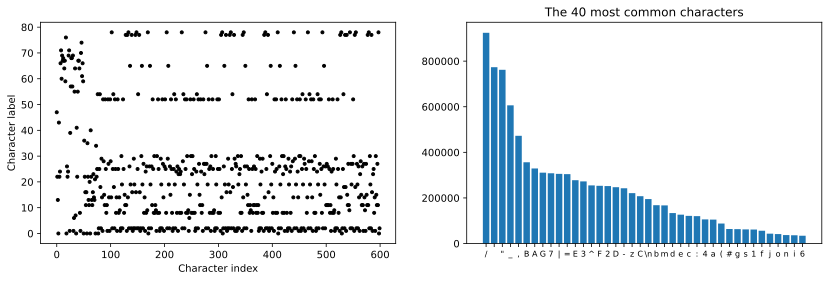

In [12]:
# convert the whole text from characters into numbers
train_data = torch.tensor(encode(train_text), dtype=torch.long)
val_data   = torch.tensor(encode(val_text),   dtype=torch.long)

# let's see the data! (left: the first 600 characters; right: how often each character appears)
fig,axs = plt.subplots(1,2,figsize=(14,4))
axs[0].plot(train_data[:600].numpy(),'k.')
axs[0].set_xlabel('Character index')
axs[0].set_ylabel('Character label')

counts = torch.bincount(train_data, minlength=vocab_size).numpy()
order = np.argsort(counts)[::-1][:40]
axs[1].bar(range(40), counts[order])
axs[1].set_xticks(range(40))
axs[1].set_xticklabels([repr(number2letter[i])[1:-1] for i in order], fontsize=8)
axs[1].set_title('The 40 most common characters')
plt.show()

❓ **Questions**
4. Which characters are the most common? Why is `/` so frequent in jazz solos (and not in folk tunes)? And `_`?
5. A model that always guesses uniformly among the characters would have a loss of $\ln(\text{vocab size})$. Compute it. We will compare our training loss with this number.

# Part 2 · The model (15 min)

The LSTM in `loremipsum` reads one character at a time and squeezes everything it has read into a hidden state.
A transformer keeps *all* previous characters and, for every new character, asks: **which earlier characters should I look at?**
That's **self-attention**. In jazz ABC, useful things to look at might be: the last chord symbol, the last bar line (to count beats), the same place one chorus ago…

### The heart of the transformer: self-attention in 10 lines

In [13]:
def self_attention(x, Wq, Wk, Wv):
  # x: one vector per character, shape (T, C) = (number of characters, embedding size)
  q = x @ Wq                                      # queries: "what am I looking for?"
  k = x @ Wk                                      # keys:    "what do I contain?"
  v = x @ Wv                                      # values:  "what do I pass on if you pick me?"
  scores = q @ k.T / math.sqrt(k.shape[-1])       # (T, T): how well each query matches each key
  T = x.shape[0]
  mask = torch.tril(torch.ones(T, T)).bool()      # causal mask: True for the past and the present
  scores = scores.masked_fill(~mask, float('-inf'))   # the future gets -inf ...
  weights = F.softmax(scores, dim=-1)             # ... so softmax gives it 0. Each row sums to 1
  return weights @ v, weights                     # each output = weighted average of the values

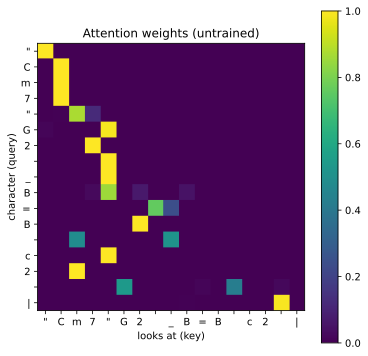

In [14]:
# try it on a little bit of jazz with random (untrained) weights
snippet = '"Cm7"G2 _B=B c2 |'
C = 16                                            # embedding size for this toy example
x = torch.randn(len(snippet), C)                  # random "embeddings", one per character
Wq, Wk, Wv = torch.randn(C, C), torch.randn(C, C), torch.randn(C, C)
out, weights = self_attention(x, Wq, Wk, Wv)

plt.figure(figsize=(6,6))
plt.imshow(weights, cmap='viridis')
plt.xticks(range(len(snippet)), list(snippet))
plt.yticks(range(len(snippet)), list(snippet))
plt.xlabel('looks at (key)')
plt.ylabel('character (query)')
plt.title('Attention weights (untrained)')
plt.colorbar()
plt.show()

❓ **Questions**
6. Why is the upper-right triangle empty? What would go wrong during training without the mask?
7. Each row sums to 1. What does row 0 look like, and why?
8. `self_attention` does not care about the *order* of the characters (try shuffling the rows of `x`). How does the model then know where a character is? (Hint: look for `pos` below.)

### The full model

The real model adds three things around `self_attention`:
* **several heads** working in parallel (each head can look for something different),
* an **MLP** (the feed-forward network from the ANN section) after attention, plus LayerNorm and residual connections: together, one **Block**,
* **embeddings** at the input: a token embedding (which character?) plus a **positional embedding** (where in the context?), and a linear layer at the output that scores each of the `vocab_size` characters.

In [15]:
# meta-parameters
block_size = 256   # context length: how many characters the model can see (≈ 8-10 bars)
n_embd     = 256   # embedding size: each character becomes a vector of 256 numbers
n_head     = 4     # attention heads per block
n_layer    = 4     # number of blocks
dropout    = 0.1   # regularization (see the DUDL regularization section)

In [16]:
class CausalSelfAttention(nn.Module):
  # the self_attention function above, with n_head heads at once and learnable weights
  def __init__(self, n_embd, n_head, block_size, dropout):
    super().__init__()
    self.n_head = n_head
    self.qkv  = nn.Linear(n_embd, 3*n_embd)      # Wq, Wk and Wv in one matrix
    self.proj = nn.Linear(n_embd, n_embd)        # mixes the heads back together
    self.drop = nn.Dropout(dropout)
    self.register_buffer('mask', torch.tril(torch.ones(block_size, block_size)).bool())
    self.att = None                              # we keep the last attention weights for Part 6

  def forward(self, x):
    B, T, C = x.shape                            # batch, time (characters), channels
    q, k, v = self.qkv(x).split(C, dim=2)
    # split the channels into heads: (B, n_head, T, C/n_head)
    q = q.view(B, T, self.n_head, C//self.n_head).transpose(1, 2)
    k = k.view(B, T, self.n_head, C//self.n_head).transpose(1, 2)
    v = v.view(B, T, self.n_head, C//self.n_head).transpose(1, 2)
    scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])
    scores = scores.masked_fill(~self.mask[:T, :T], float('-inf'))
    att = F.softmax(scores, dim=-1)
    self.att = att.detach()
    y = self.drop(att) @ v
    y = y.transpose(1, 2).reshape(B, T, C)       # glue the heads back together
    return self.proj(y)


class Block(nn.Module):
  # attention (look around) + MLP (think about it), each with LayerNorm and a residual connection
  def __init__(self, n_embd, n_head, block_size, dropout):
    super().__init__()
    self.ln1  = nn.LayerNorm(n_embd)
    self.attn = CausalSelfAttention(n_embd, n_head, block_size, dropout)
    self.ln2  = nn.LayerNorm(n_embd)
    self.mlp  = nn.Sequential(nn.Linear(n_embd, 4*n_embd), nn.GELU(),
                              nn.Linear(4*n_embd, n_embd), nn.Dropout(dropout))

  def forward(self, x):
    x = x + self.attn(self.ln1(x))
    x = x + self.mlp(self.ln2(x))
    return x


class MusicGPT(nn.Module):
  def __init__(self, vocab_size, block_size=256, n_embd=256, n_head=4, n_layer=4, dropout=0.1, use_pos=True):
    super().__init__()
    self.config = dict(vocab_size=vocab_size, block_size=block_size, n_embd=n_embd,
                       n_head=n_head, n_layer=n_layer, dropout=dropout, use_pos=use_pos)
    self.block_size = block_size
    self.use_pos = use_pos
    self.tok_emb = nn.Embedding(vocab_size, n_embd)      # which character?
    self.pos_emb = nn.Embedding(block_size, n_embd)      # where in the context?
    self.drop    = nn.Dropout(dropout)
    self.blocks  = nn.Sequential(*[Block(n_embd, n_head, block_size, dropout) for _ in range(n_layer)])
    self.ln_f    = nn.LayerNorm(n_embd)
    self.head    = nn.Linear(n_embd, vocab_size)         # a score for every possible next character

  def forward(self, idx):
    B, T = idx.shape
    x = self.tok_emb(idx)                                # (B, T, n_embd)
    if self.use_pos:
      x = x + self.pos_emb(torch.arange(T, device=idx.device))
    x = self.blocks(self.drop(x))
    return self.head(self.ln_f(x))                       # (B, T, vocab_size)

In [17]:
# model instance
model = MusicGPT(vocab_size, block_size, n_embd, n_head, n_layer, dropout).to(device)

# count the parameters (see DUDL_ANN_numParameters)
nparams = sum(p.numel() for p in model.parameters())
print(f'MusicGPT: {nparams:,} parameters')
for name, part in [('token embedding', model.tok_emb), ('positional embedding', model.pos_emb),
                   ('one block', model.blocks[0]), ('output layer', model.head)]:
  print(f'  {name:22s} {sum(p.numel() for p in part.parameters()):>10,}')

# for comparison: the LSTM of DUDL_RNN_loremipsum (hidden_size=512, num_layers=3) on our vocabulary
lstm = nn.LSTM(vocab_size, 512, 3)
print(f'\nloremipsum LSTM: {sum(p.numel() for p in lstm.parameters()):,} parameters')

MusicGPT: 3,265,615 parameters
  token embedding            20,224
  positional embedding       65,536
  one block                 789,760
  output layer               20,303

loremipsum LSTM: 5,416,960 parameters


❓ **Questions**
9. Where are most of the parameters? Compute by hand the parameters of one block (hint: `qkv` is 256×768 + 768, the MLP is 256×1024 + 1024 + 1024×256 + 256, plus `proj` and two LayerNorms).
10. The loremipsum LSTM is even bigger than our GPT. Which one do you expect to train faster on a GPU, and why? (Think: can an LSTM process the 256 characters of a sequence in parallel?)

# Part 3 · Training (15–20 min, GPU)

Same recipe as `loremipsum`: input `x` = a piece of text, target `y` = the same piece **shifted by one character**, `CrossEntropyLoss`, Adam. Two differences:
* we take a **batch of 64 random pieces** of 256 characters at a time, instead of walking through the text;
* thanks to the causal mask, the model predicts **all 256 next characters in parallel** in one forward pass.

**Perplexity** = $e^{\text{loss}}$: "the model is as unsure as if it had to choose between *N* equally likely characters". Uniform guessing gives *N* = vocab size.

In [18]:
def get_batch(data, batch_size=64, block_size=256):
  # random starting points, then input x and target y (shifted version of x, as in loremipsum)
  ix = torch.randint(len(data) - block_size - 1, (batch_size,))
  x = torch.stack([data[i   : i+block_size  ] for i in ix])
  y = torch.stack([data[i+1 : i+block_size+1] for i in ix])
  return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss(model, data, n_batches=20):
  # average loss over some random batches, with dropout switched off
  model.eval()
  losses = []
  for _ in range(n_batches):
    x, y = get_batch(data, 64, model.block_size)
    logits = model(x)
    losses.append(F.cross_entropy(logits.view(-1, logits.shape[-1]), y.view(-1)).item())
  model.train()
  return float(np.mean(losses))                # a plain Python number (safe to save with torch.save)

x, y = get_batch(train_data, batch_size=2, block_size=40)
print('x:', repr(decode(x[0])))
print('y:', repr(decode(y[0])))

x: 'C."z2 "N.C."z2 "N.C."z_B|(3"Bb7#5"_d_B_c'
y: '."z2 "N.C."z2 "N.C."z_B|(3"Bb7#5"_d_B_c '


In [19]:
def save_run(path, model, checkpoints, losses):
  torch.save(dict(config=model.config, vocab=uniquecharacters, checkpoints=checkpoints, losses=losses), path)

def train_model(model, max_steps=3000, batch_size=64, learning_rate=1e-3,
                save_steps=(), run_name='music_gpt', eval_every=100, plot_every=250):
  lossfun   = nn.CrossEntropyLoss()
  optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
  losses = dict(step=[], train=[], val=[])
  checkpoints = {}
  t0 = time.time()

  for step in range(1, max_steps+1):
    # get input and target (shifted version of input)
    x, y = get_batch(train_data, batch_size, model.block_size)

    # forward pass and loss: every position predicts its next character
    logits = model(x)                                   # (batch, block_size, vocab_size)
    loss = lossfun(logits.view(-1, logits.shape[-1]), y.view(-1))

    # backprop
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # from time to time: measure train and validation loss
    if step % eval_every == 0 or step == 1:
      losses['step'].append(step)
      losses['train'].append(estimate_loss(model, train_data))
      losses['val'].append(estimate_loss(model, val_data))

    # keep a copy of the weights at some steps (and save them, in case Colab disconnects)
    if step in save_steps:
      checkpoints[step] = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
      save_run(os.path.join(SAVE_DIR, run_name + '.pt'), model, checkpoints, losses)

    # live plot
    if step % plot_every == 0 or step == max_steps:
      clear_output(wait=True)
      plt.figure(figsize=(8,4))
      plt.plot(losses['step'], losses['train'], label='train')
      plt.plot(losses['step'], losses['val'], label='validation')
      plt.axhline(np.log(vocab_size), color='gray', linestyle='--', label='uniform guessing')
      plt.xlabel('Training step'); plt.ylabel('Loss'); plt.legend(); plt.ylim(0, 5)
      plt.title(f'step {step}/{max_steps} · val loss {losses["val"][-1]:.3f} · '
                f'perplexity {np.exp(losses["val"][-1]):.2f} · {time.time()-t0:.0f} s')
      plt.show()

  return losses, checkpoints

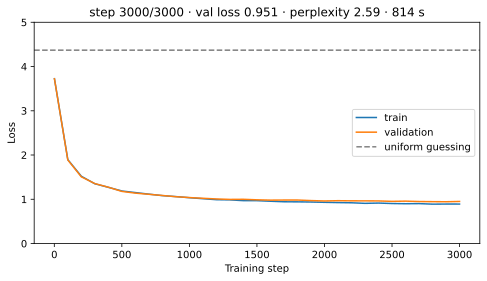

In [20]:
#@title Train (≈ 10 min on a T4 GPU)
TRAIN = True        #@param {type:"boolean"}
max_steps = 3000    #@param {type:"integer"}
save_steps = [200, 1000, 3000]
RUN_NAME = 'e2_jazz_gpt'

if TRAIN:
  torch.manual_seed(0)
  model = MusicGPT(vocab_size, block_size, n_embd, n_head, n_layer, dropout).to(device)
  losses, checkpoints = train_model(model, max_steps=max_steps, save_steps=save_steps, run_name=RUN_NAME)

**No GPU / training failed?** Use the teacher's checkpoint: set `TRAIN = False` above, then run the next cell.
It loads `e2_jazz_gpt.pt` from your `SAVE_DIR` (put it there via Drive) or downloads it from `FALLBACK_URL`.

In [21]:
#@title Load a saved run (your own, or the teacher's fallback)
FALLBACK_URL = ''   #@param {type:"string"}

def load_run(path):
  global uniquecharacters, number2letter, letter2number, vocab_size
  run = torch.load(path, map_location='cpu')
  if run['vocab'] != uniquecharacters:      # make sure we use the vocabulary the model was trained with
    print('Using the vocabulary stored in the checkpoint.')
    uniquecharacters = run['vocab']
    number2letter = dict(enumerate(uniquecharacters))
    letter2number = { l:i for i,l in number2letter.items() }
    vocab_size = len(uniquecharacters)
  model = MusicGPT(**run['config']).to(device)
  model.load_state_dict(run['checkpoints'][max(run['checkpoints'])])
  return model, run['checkpoints'], run['losses']

if not TRAIN:
  path = os.path.join(SAVE_DIR, RUN_NAME + '.pt')
  if not os.path.exists(path) and FALLBACK_URL:
    urllib.request.urlretrieve(FALLBACK_URL, path)
  model, checkpoints, losses = load_run(path)
  print('Loaded checkpoints at steps', sorted(checkpoints))

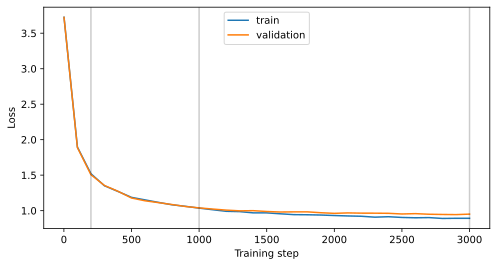

final validation loss 0.951 → perplexity 2.59 (uniform guessing: 79)


In [22]:
# check out the losses
plt.figure(figsize=(8,4))
plt.plot(losses['step'], losses['train'], label='train')
plt.plot(losses['step'], losses['val'], label='validation')
for s in sorted(checkpoints):
  plt.axvline(s, color='k', alpha=.2)
plt.xlabel('Training step'); plt.ylabel('Loss'); plt.legend()
plt.show()
print(f'final validation loss {losses["val"][-1]:.3f} → perplexity {np.exp(losses["val"][-1]):.2f} '
      f'(uniform guessing: {vocab_size})')

❓ **Questions**
11. Compare the first loss with $\ln(\text{vocab size})$ from question 5. Why does training start there?
12. A perplexity of about 3 means: on average the model hesitates between ~3 characters. Where in a jazz ABC line is the next character easy to guess, and where is it hard?
13. Is the model overfitting (validation loss going up while training loss goes down)? What could you change if it were? (Challenge 5 trains on the solos in their original keys only: compare its curves with yours.)

# Part 4 · The learning curve you can hear (30 min)

`generate` writes music one character at a time: run the model, turn the scores of the **next** character into probabilities, roll the dice, append the character, repeat. (`loremipsum` always took the most likely character, `argmax`; here we sample.)

**Expect broken ABC at the early checkpoints.** At step 200 the model has not yet learned that a chord symbol needs a closing `"`, or which letters can appear in a bar: you will see a ⚠ line under the sheet music (abcjs skips what it cannot read), and `report()` counts these as *invalid characters*. That is part of the learning curve, not a bug: watch the number go down at steps 1000 and 3000.

In [23]:
@torch.no_grad()
def generate(model, prompt, max_new_chars=1200, temperature=1.0, top_k=None):
  model.eval()
  idx = torch.tensor([encode(prompt)], device=device)
  out = prompt
  for _ in range(max_new_chars):
    logits = model(idx[:, -model.block_size:])     # only the last block_size characters fit
    logits = logits[0, -1, :] / temperature        # scores of the NEXT character, reshaped by the temperature
    if top_k is not None:                          # keep only the k best candidates
      kth_best = torch.topk(logits, top_k).values[-1]
      logits[logits < kth_best] = -float('inf')
    probs = F.softmax(logits, dim=-1)              # scores -> probabilities
    next_char = torch.multinomial(probs, 1)        # roll the dice
    idx = torch.cat([idx, next_char.view(1, 1)], dim=1)
    out += number2letter[next_char.item()]
    if out.endswith('|]') or out.endswith('\n\n'): # end of the chorus
      break
    if out.endswith('\nX:'):                      # the model started a new tune: stop before it
      out = out[:-3]
      break
  model.train()
  return out

def report(tune):
  c = check_abc(tune)
  print(f"{c['n_bars']} bars · {100*c['bar_ok']:.0f}% with the right length · "
        f"{c['errors']} invalid characters · finished: {c['finished']} · "
        f"{100*chord_tone_ratio(tune):.0f}% of the notes on chord tones (real solos ≈ 50%)")

In [24]:
prompt = make_prompt(soloist='Charlie Parker (as)', style='bebop, swing', tempo=200, key='Bb', title='Blues for E2')
print(prompt)

for step in sorted(checkpoints):
  model.load_state_dict(checkpoints[step])
  torch.manual_seed(1)
  tune = generate(model, prompt, temperature=0.9)
  print(f'\n================  step {step}  ================')
  print(tune[len(prompt):][:500])
  report(tune)
  show_abc(tune, midi_name=f'step{step}')

X:1
T:Blues for E2
C:Charlie Parker (as)
R:bebop, swing
M:4/4
L:1/8
Q:1/4=200
K:Bb




================  step 200  ================
"A6- c _B_E _B|"Ab"_A2F2- F_B3 (3c_B_Bc|"Bb"cc/- c2-|"Gm"_d3/- d2 d/_e/- d/d/e/ "Ama2 c|
"Cm7"cd d2 "F/A/A/ (3:2:2C7"A/G_A _G2|"Fm7"D/=A/ G,G,_B,-|"Gb7"G, G_G,G,,|"_G7"_G,/_E,=E, "C2 "F7"=E/_G/=E/|"c/z8|
"Dm7"z3"z=e "A/=B/A/B/ "A/ d d_A7"G/_d/_A/ (3/ f_A7"B_Bd _B_Bd/|"A7"c/c/_B/_B/_a/- "Eb/_B/f/d/ _ed/d- f/c'_d/_d/|"G7"B/^g3/B2 (3/cc_A|
"Dm7"_AG/_E/_B/ "_D/G/G/G/_B/^F/ G/_E/_G/C/- F/G/_A/|(3"Cm7"_d/C_e=ff/_e/B/_e/- =d|"Amaj7"gf'ug/_g/- z/g/f/a/_e/-|"Eb7"C#5"_d/_g _A#"f_B/_g/=B/=A/-|
"Am7bm7"=d4z
20 bars · 5% with the right length · 23 invalid characters · finished: False · 28% of the notes on chord tones (real solos ≈ 50%)



================  step 1000  ================
"Bb7"z2 z3/F/ _E2 A3/_G/|(3"Bb7"_A_Gz z3/_A/- _A/z3/ z2|"Eb7"z_A _A/_A/G/ _A/_G/A/_B/ (3_AC_EF|"Ab7"=E/_D/F/_E/ _AC _B,/_A,/F,/=A,/-|
"Ab7"=A,/_D/_E/ F_A/_B/=B/ F/_A _d/^c/_B/=c/ ^F/A/_B/=B/|(3"Dm7"c_A_E (3=F_A_B =e/=e/=B/A/ _A/_B/_B/_A/|"G7"_A/_B/_A F_A _B/z3/ z2|"F7"zD/c/ (3_Bcc _a_b/a/- _b/f_d/|
"Bbm7"f_e3- (3_d=B_B =A^F|"Bb7"_Ac3/=A/_A/c/_A/ _E/_A_B/ _B2-|"Gbmaj7"_B/=B_B/- _B/=B^F/ (3=F_E=E|"Db7"_e=f =e/z3/ z4|
"Gbmaj7"z3/=F/- F/_E/_B,/ =B,_G- _G/_A_B/|"Cmaj7"BA _A_B c_E D2|"Fm7"=A2- A/G=F/ 
33 bars · 52% with the right length · 1 invalid characters · finished: False · 41% of the notes on chord tones (real solos ≈ 50%)



================  step 3000  ================
"Bb7"z2 F_E F_A _Bc|"Bb7"_ef _d_e _Bz z3/_A/-|"Eb7"_Ac _e_d c_B _A_G-|"Bb7"_G_B _A_G2F _E_E|
"Bb7"F_A F_B, _A,F, _A,_B,|"Bb7"CD F_A _B=A _G=G-|"Db7"GG _A_B _GF _E_D|"Ddim"C_B, =B,_E "Eb6"=EF _A=B|
"Ab"_EF _EF _G_A _B=A/=B/-|"Db7"=B_B _A_B =A_B _A_B|"Ab7"F_B z2 _B2 _B3/_D/|"Db7"_B,2 _D2 _E2 _B,_A,-|
"Gb7"_A,2 _A,_B, _D_E F_A|"B7"_B_A _AF _D_E _G_A|"Bb7"F_E DF _AF D_E|"Bb7"_D2 _DC2_B, G,2|
"F7"F,2 z6|]
17 bars · 100% with the right length · 0 invalid characters · finished: True · 42% of the notes on chord tones (real solos ≈ 50%)


❓ **Questions** (listen first, then answer)
14. Step 200: what has the model already learned? (characters? bar lines? chord symbols?) What is missing?
15. Step 1000 vs step 3000: does it get the bar length right? Does it follow the chord symbols (listen, then check the chord-tone % in the report)? Does it end the chorus?
16. In which order did the model learn these things? Why do you think the "easy" things come first?

# Part 5 · Sampling, real chord changes, your own prompt (40 min)

* **temperature** < 1 makes the likely characters even more likely (safe, repetitive); > 1 flattens the distribution (adventurous, more mistakes).
* **top-k** only allows the *k* most likely characters (cuts off the long tail of nonsense).
* The **prompt** is everything the model reads before writing. The header lines are a kind of *conditioning*: we will look at this properly in E3.

In [25]:
model.load_state_dict(checkpoints[max(checkpoints)])   # the last checkpoint

for temperature in [0.7, 0.9, 1.2]:
  torch.manual_seed(2)
  tune = generate(model, prompt, temperature=temperature)
  print(f'\n================  temperature {temperature}  ================')
  report(tune)
  show_abc(tune, midi_name=f'temp{temperature}')


================  temperature 0.7  ================
24 bars · 96% with the right length · 0 invalid characters · finished: True · 49% of the notes on chord tones (real solos ≈ 50%)



================  temperature 0.9  ================
54 bars · 94% with the right length · 0 invalid characters · finished: False · 54% of the notes on chord tones (real solos ≈ 50%)



================  temperature 1.2  ================
30 bars · 97% with the right length · 0 invalid characters · finished: True · 41% of the notes on chord tones (real solos ≈ 50%)


❓ **Questions**
17. At temperature 0.7, 0.9 and 1.2: which is the most *musical*? Which has the most *valid bars*? Are these the same? Compare the chord-tone % and listen to the **rests**: what does a low temperature do to the phrasing, and why? (Hint: a rest or the end of a chorus is never the single most likely next character.)
18. Try `top_k = 5` with `temperature = 1.2` (in the form below). Does top-k "repair" the high temperature?

## Give it real chord changes

Read the chord symbols of the solos above: the model **invents its own changes**, and they wander (we asked for a blues, but there is no 12-bar blues form). Its line then tends to stay in the key while the chords move, and the walking bass makes every mismatch easy to hear.

A jazz musician never improvises over random chords: there is a **lead sheet**. So let's give the model one. `generate_over` writes the chord of every bar itself, right after each `|` (and at beat 3 when a bar has two chords), and it does not allow the model to write a `"`: the model only plays the solo. The model was never trained to do this; it simply reads our chord symbols the same way it reads its own. This is conditioning *during* generation; E3 goes further.

In [26]:
@torch.no_grad()
def generate_over(model, prompt, changes, choruses=1, temperature=1.0, top_k=None, max_new_chars=4000):
  bars = [b.split() for b in changes.split('|') if b.strip()] * choruses
  ours = [letter2number[c] for c in '"]\n']        # chord symbols, the end of the tune and line breaks are our job
  body = abc_body(prompt)
  n = body.count('|')                              # bars already written in the prompt
  current = body[body.rfind('|')+1:]               # the unfinished bar
  if n >= len(bars):
    return prompt
  todo = [] if '"' in current else [(8*i//len(bars[n]), c) for i, c in enumerate(bars[n])]  # (8th note, chord)
  model.eval()
  out = prompt
  for _ in range(max_new_chars):
    # our next chord, as soon as the bar has reached its beat (and the model has finished a note)
    if todo and (current.strip() == '' or out.endswith(' ')) and bar_time(current) >= todo[0][0]:
      chord = '"' + todo.pop(0)[1] + '"'
      out, current = out + chord, current + chord
    logits = model(torch.tensor([encode(out[-model.block_size:])], device=device))[0, -1] / temperature
    logits[ours] = -float('inf')                   # the model may not write these characters
    if top_k is not None:
      logits[logits < torch.topk(logits, top_k).values[-1]] = -float('inf')
    next_char = number2letter[torch.multinomial(F.softmax(logits, dim=-1), 1).item()]
    out += next_char
    if next_char != '|':
      current += next_char
      continue
    n += 1                                         # a bar line: on to the next bar of the lead sheet
    if n == len(bars):
      out += ']'
      break
    out += '\n' if n % 4 == 0 else ''              # 4 bars per line, as in the data
    current, todo = '', [(8*i//len(bars[n]), c) for i, c in enumerate(bars[n])]
  model.train()
  return out

In [27]:
blues = lead_sheet('blues', 'Bb')      # see LEAD_SHEETS: 'blues', 'minor blues', 'rhythm changes', 'ii-V-I', 'modal'
print('lead sheet:', blues)

torch.manual_seed(3)
free = generate(model, prompt, temperature=0.9)
over = generate_over(model, prompt, blues, choruses=2, temperature=0.9)
for name, tune in [('free', free), ('over_a_Bb_blues', over)]:
  print(f'\n================  {name}  ================')
  print('chords:', ' '.join(re.findall(r'"([^"]*)"', abc_body(tune)))[:150])
  report(tune)
  show_abc(tune, midi_name=name)

lead sheet: Bb7 | Eb7 | Bb7 | Bb7 | Eb7 | Edim7 | Bb7 | G7 | Cm7 | F7 | Bb7 G7 | Cm7 F7



================  free  ================
chords: N.C. N.C. Bb7 Bb7 Eb7 Bb7 Bb7 Bb7 Dm7 G7 Dm7 Bb9 C7 Bb9 Bb9 Bb9 Am7 Am7 D7 Gm7 C7 Bb9 F9 F9 Bb9#11 C7 F9#11 F9#11 F9#11 F9#11 F9#11 F9#11 A9#11 A9#11 
42 bars · 95% with the right length · 0 invalid characters · finished: True · 44% of the notes on chord tones (real solos ≈ 50%)



================  over_a_Bb_blues  ================
chords: Bb7 Eb7 Bb7 Bb7 Eb7 Edim7 Bb7 G7 Cm7 F7 Bb7 G7 Cm7 F7 Bb7 Eb7 Bb7 Bb7 Eb7 Edim7 Bb7 G7 Cm7 F7 Bb7 G7 Cm7 F7
24 bars · 100% with the right length · 0 invalid characters · finished: True · 43% of the notes on chord tones (real solos ≈ 50%)


❓ **Questions**
19. Listen to both, and read the chord line of each. Which one sounds more like a jazz solo, and why? Does the free solo keep a blues form? (The chord-tone % changes a lot from one solo to the next: over 30 solos it was 47 % free and 50 % over the blues, the same as real solos.)
20. Try `lead_sheet('rhythm changes', 'Bb')` (two chords in most bars, a new key area in the bridge) or write your own changes (`'Dm7 G7 | Cmaj7 | ...'`). Does the model follow fast changes as well as the blues? Where does it get lost?

In [28]:
#@title Your prompt
soloist = 'John Coltrane (ts)'   #@param ['Charlie Parker (as)', 'John Coltrane (ts)', 'Sonny Rollins (ts)', 'Miles Davis (tp)', 'Clifford Brown (tp)', 'Chet Baker (tp)', 'Dexter Gordon (ts)', 'Stan Getz (ts)', 'Lee Konitz (as)', 'Michael Brecker (ts)', 'Pat Metheny (g)', 'J.J. Johnson (tb)'] {allow-input: true}
style = 'hardbop, swing'         #@param ['traditional, twobeat', 'swing era, swing', 'bebop, swing', 'cool, swing', 'hardbop, swing', 'postbop, swing', 'postbop, latin', 'fusion, funk'] {allow-input: true}
key = 'Eb'                       #@param ['C', 'F', 'Bb', 'Eb', 'Ab', 'Db', 'G', 'D', 'Cm', 'Fm', 'Gm', 'Dm'] {allow-input: true}
tempo = 180                      #@param {type:"slider", min:60, max:320, step:10}
title = 'Blues for E2'           #@param {type:"string"}
changes = 'blues'                #@param ['free', 'blues', 'minor blues', 'rhythm changes', 'ii-V-I', 'modal'] {allow-input: true}
# changes: 'free' = the model writes its own chords; a form = we write them, in your key; or type your own: 'Dm7 G7 | Cmaj7 | ...'
first_bars = '"Eb7"B2 GB cB GF|"Ab7"' #@param {type:"string"}
# first_bars: normal ABC is fine (B in K:Eb is a B flat); make_prompt rewrites it the way the model learned it
temperature = 0.9                #@param {type:"slider", min:0.1, max:2.0, step:0.1}
top_k = 0                        #@param {type:"integer"}

if changes in MINOR_FORMS and not key.endswith('m'):
  key += 'm'                                     # a minor form needs a minor key
my_prompt = make_prompt(soloist, style, tempo, key, title, first_bars)
if changes == 'free':
  tune = generate(model, my_prompt, temperature=temperature, top_k=top_k if top_k > 0 else None)
else:
  sheet = lead_sheet(changes, key) if changes in LEAD_SHEETS else changes
  print('lead sheet:', sheet)
  tune = generate_over(model, my_prompt, sheet, temperature=temperature, top_k=top_k if top_k > 0 else None)
print(tune)
report(tune)
show_abc(tune, midi_name='my_tune')

lead sheet: Eb7 | Ab7 | Eb7 | Eb7 | Ab7 | Adim7 | Eb7 | C7 | Fm7 | Bb7 | Eb7 C7 | Fm7 Bb7


X:1
T:Blues for E2
C:John Coltrane (ts)
R:hardbop, swing
M:4/4
L:1/8
Q:1/4=180
K:Eb
"Eb7"_B2 G_B c_B GF|"Ab7"_A=A (3_AGE (3C_EC G,2|"Eb7"z8|"Eb7"z/_E/_A/_E/- _EG _B3/_G/- _G=G|
"Ab7"_B3/G/- G_E _G_E _D2|"Adim7"_E4 _E_D C=B,|"Eb7"_B,_G, z6|"C7"gf3/_ec/- c_B G_B|
"Fm7"_A_B G_E C_B,2z|"Bb7"z_B, (3C_EF _ED C_B,|"Eb7"_A,2 _B,G, "C7"_A,G, _E,C,|"Fm7"_B,_E FG "Bb7"_B_A =A2|]
12 bars · 100% with the right length · 0 invalid characters · finished: True · 61% of the notes on chord tones (real solos ≈ 50%)


❓ **Questions**
21. Set `changes = 'free'` and write your own first bar (a lick you like, with a chord symbol) in `first_bars`. Does the model continue in the same style? Does it keep the chord changes going?
22. Change only the soloist (same key, tempo, style). Can you *hear* a difference? With `changes = 'free'`, change the title to `Giant Steps` or `Anthropology`. What happens to the chord changes, and why?

# Part 6 · Look inside: attention maps (20 min)

Every head of every block has an attention matrix like the toy one in Part 2. Let's feed a chorus the model has **never seen** (from the validation set) and look for heads with a musical job:
* **bar-line heads**: when the model writes `|`, does it look at the previous `|`? (counting the beats in the bar)
* **harmony heads**: when the model writes a note, does it look at the current chord symbol?

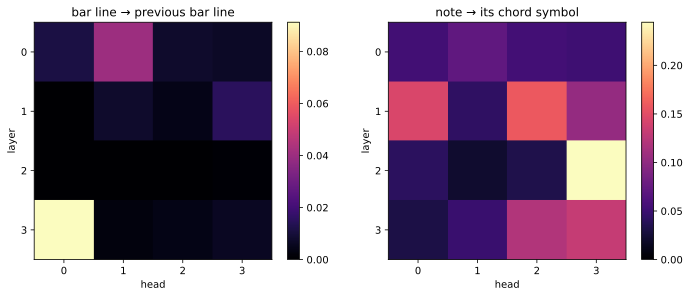

best bar-line head (layer, head): (3, 0)
best harmony head  (layer, head): (2, 3)


In [29]:
# run the model on the first block_size characters of a validation chorus
tune = val_tunes[3]
body_start = tune.index('K:')
window = tune[body_start : body_start + model.block_size]
model.eval()
with torch.no_grad():
  model(torch.tensor([encode(window)], device=device))
att = torch.stack([blk.attn.att[0] for blk in model.blocks]).cpu()   # (n_layer, n_head, T, T)
T = len(window)

# where are the bar lines and the chord symbols?
bars = [i for i, c in enumerate(window) if c == '|']
chord_of = np.full(T, -1)                     # for each position: start of the last chord symbol
spans = [(m.start(), m.end()) for m in re.finditer(r'"[^"]*"', window)]
for s, e in spans:
  chord_of[e:] = s
notes = [i for i, c in enumerate(window) if c in 'ABCDEFGabcdefg' and chord_of[i] >= 0 and
         not any(s <= i < e for s, e in spans)]

# score of each head: attention from a bar line to the previous bar line,
# and from a note to (all characters of) its chord symbol
bar_score = np.zeros(att.shape[:2]); chord_score = np.zeros(att.shape[:2])
for l in range(att.shape[0]):
  for h in range(att.shape[1]):
    A = att[l, h].numpy()
    bar_score[l, h] = np.mean([A[b2, b1] for b1, b2 in zip(bars[:-1], bars[1:])])
    chord_score[l, h] = np.mean([A[i, chord_of[i]:window.index('"', chord_of[i]+1)+1].sum() for i in notes])

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, S, name in zip(axs, [bar_score, chord_score], ['bar line → previous bar line', 'note → its chord symbol']):
  im = ax.imshow(S, cmap='magma', vmin=0)
  ax.set_xlabel('head'); ax.set_ylabel('layer'); ax.set_title(name)
  ax.set_xticks(range(S.shape[1])); ax.set_yticks(range(S.shape[0]))
  plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()
print('best bar-line head (layer, head):', tuple(int(i) for i in np.unravel_index(bar_score.argmax(), bar_score.shape)))
print('best harmony head  (layer, head):', tuple(int(i) for i in np.unravel_index(chord_score.argmax(), chord_score.shape)))

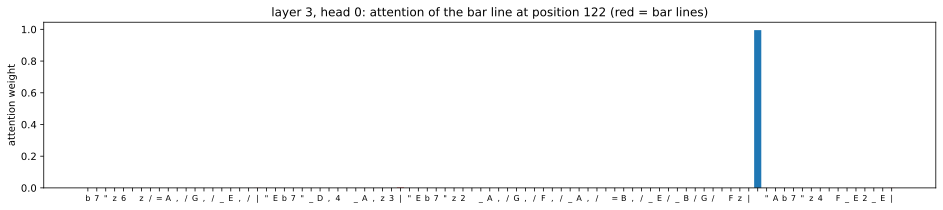

In [30]:
#@title Where does one head look while the model writes a bar line?
layer = -1     #@param {type:"integer"}
head = -1      #@param {type:"integer"}
which_bar = 4  #@param {type:"integer"}
# -1 = use the best bar-line head found above
if layer < 0 or head < 0:
  layer, head = np.unravel_index(bar_score.argmax(), bar_score.shape)

q = bars[which_bar]
A = att[layer, head, q, :q+1].numpy()
start = max(0, q - 90)
plt.figure(figsize=(16, 3))
plt.bar(range(start, q+1), A[start:], color=['C3' if window[i] == '|' else 'C0' for i in range(start, q+1)])
plt.xticks(range(start, q+1), list(window[start:q+1]), fontsize=8)
plt.title(f'layer {layer}, head {head}: attention of the bar line at position {q} (red = bar lines)')
plt.ylabel('attention weight')
plt.show()

❓ **Questions**
23. Use the scores to pick a layer and head. Does the "bar-line head" really look at the previous `|`? Or at something else (the last space = the last beat? the chord?)
24. Find the harmony head and plot it for a note instead of a bar line (change `q`). Which characters of the chord symbol does it use?
25. Attention maps are a nice story, but are they an *explanation*? What else would you need to show that this head really counts beats?

# ★ Code challenges (optional)

Each retraining takes about as long as Part 3. Use `max_steps=1500` to save time, and compare with your Part 3 losses at step 1500.

**1. Context length.** Train a model with `block_size=32` (about one bar). Can it keep the bar length right? Does it keep the chord progression going? Does it end the chorus?

In [31]:
# 1) context length 32 vs 256
# model32 = MusicGPT(vocab_size, block_size=32).to(device)
# losses32, ckpts32 = train_model(model32, max_steps=1500, save_steps=[1500], run_name='ctx32')
# tune = generate(model32, prompt, temperature=0.9); report(tune); show_abc(tune)

**2. LSTM vs Transformer.** The LSTM from `loremipsum`, with `batch_first=True` so it takes our batches, and an embedding of 256 like our GPT. Compare the validation loss at the same step, the time per step, and the samples.

In [32]:
class lstmnet(nn.Module):
  def __init__(self, vocab_size, emb_size=256, hidden_size=512, num_layers=2, block_size=256):
    super().__init__()
    self.config = dict(vocab_size=vocab_size, emb_size=emb_size, hidden_size=hidden_size,
                       num_layers=num_layers, block_size=block_size)
    self.block_size = block_size                   # only used by get_batch and generate
    self.embedding = nn.Embedding(vocab_size, emb_size)
    self.lstm = nn.LSTM(emb_size, hidden_size, num_layers, batch_first=True)
    self.out = nn.Linear(hidden_size, vocab_size)

  def forward(self, x):
    y, h = self.lstm(self.embedding(x))
    return self.out(y)

# lstm = lstmnet(vocab_size).to(device)
# print(f'{sum(p.numel() for p in lstm.parameters()):,} parameters')
# losses_lstm, ckpts_lstm = train_model(lstm, max_steps=1500, save_steps=[1500], run_name='lstm')
# tune = generate(lstm, prompt, temperature=0.9); report(tune); show_abc(tune)

**3. No positional embedding.** `MusicGPT(..., use_pos=False)`. The model has no idea *where* a character is, only *what* came before (through the mask). What happens to the bar structure? (Open question: results vary between runs. Why might the causal mask alone still give some position information?)

In [33]:
# 3) no positional embedding
# model_nopos = MusicGPT(vocab_size, use_pos=False).to(device)
# losses_nopos, ckpts_nopos = train_model(model_nopos, max_steps=1500, save_steps=[1500], run_name='nopos')

**4. Memorization check.** Is the model copying the training set? `longest_common_substring(sample, train_text)` finds the longest piece of a sample that appears in the training text. **Compare with real music**: unseen validation choruses also share fragments with the training set (jazz players reuse licks, and many tunes share chord changes).

In [34]:
# 4) memorization check
model.load_state_dict(checkpoints[max(checkpoints)])
torch.manual_seed(3)
sample = abc_body(generate(model, prompt, temperature=0.9))
copied = longest_common_substring(sample, train_text)
print(f'generated: longest copied fragment = {len(copied)} characters, {copied.count("|")} bar lines:\n  {copied!r}')

# baseline: real choruses the model has never seen
for t in val_tunes[:3]:
  c = longest_common_substring(abc_body(t)[:800], train_text)
  print(f'real (validation): {len(c)} characters')

generated: longest copied fragment = 21 characters, 1 bar lines:
  '"N.C."_ez3 z4|"N.C."z'


real (validation): 20 characters


real (validation): 19 characters


real (validation): 26 characters


**5. No data augmentation.** Train on the solos in their original keys only (`N_KEYS = 1`): 12 times less data. Compare the train and validation curves with yours. When does the validation loss stop improving? Listen to the samples: do the notes fit the chords as well?

In [35]:
# 5) original keys only
# tunes1 = [r['abc'] for r in build_dataset('wjazzd.db', n_keys=1)]
# train_data_12keys = train_data
# train_data = torch.tensor(encode('\n\n'.join(t for t in tunes1 if solo_of(t) not in val_solos) + '\n\n'), dtype=torch.long)
# model1 = MusicGPT(vocab_size, block_size, n_embd, n_head, n_layer, dropout).to(device)
# losses1, ckpts1 = train_model(model1, max_steps=3000, save_steps=[3000], run_name='one_key')
# train_data = train_data_12keys          # back to the 12-key data
# plt.plot(losses['step'], losses['val'], label='12 keys'); plt.plot(losses1['step'], losses1['val'], label='1 key')
# plt.plot(losses1['step'], losses1['train'], '--', label='1 key (train)'); plt.legend(); plt.show()

# H2 · Home: the sampling lab (1.5 h)

2 checkpoints × 3 temperatures × 5 samples = 30 tunes. For each setting the table gives:
* **valid %**: tunes with no invalid characters and at least 4 bars,
* **bars ok %**: bars with the right duration for 4/4,
* **finished %**: tunes that end the chorus with `|]`,
* **chord tones %**: notes that belong to the chord symbol above them (real solos ≈ 50 %, random notes ≈ 33 %),
* **longest copy**: the longest fragment copied from the training set (characters).

All samples are saved to `SAVE_DIR/h2_samples.abc` (open it in any ABC tool, or use `show_abc` below).

In [36]:
def sampling_lab(steps=(1000, 3000), temperatures=(0.7, 0.9, 1.2), n_samples=5, prompt=prompt, top_k=None):
  rows, samples = [], []
  for step in steps:
    model.load_state_dict(checkpoints[step])
    for temp in temperatures:
      for i in range(n_samples):
        tune = generate(model, prompt, temperature=temp, top_k=top_k)
        c = check_abc(tune)
        copy = longest_common_substring(abc_body(tune), train_text)
        rows.append(dict(step=step, temperature=temp, sample=len(samples),
                         valid=(c['errors'] == 0 and c['n_bars'] >= 4), bars_ok=c['bar_ok'],
                         finished=c['finished'], n_bars=c['n_bars'], chord_tones=chord_tone_ratio(tune),
                         longest_copy=len(copy)))
        samples.append(re.sub(r'^X:.*', f'X:{len(samples)}', tune, count=1))
  with open(os.path.join(SAVE_DIR, 'h2_samples.abc'), 'w') as f:
    f.write('\n\n'.join(samples) + '\n')
  df = pd.DataFrame(rows)
  table = df.groupby(['step', 'temperature']).agg(valid_pct=('valid', 'mean'), bars_ok_pct=('bars_ok', 'mean'),
                                                  finished_pct=('finished', 'mean'),
                                                  chord_tones_pct=('chord_tones', 'mean'),
                                                  longest_copy=('longest_copy', 'mean'))
  table[['valid_pct', 'bars_ok_pct', 'finished_pct', 'chord_tones_pct']] *= 100
  return table.round(1), df, samples

table, lab_df, lab_samples = sampling_lab()      # ≈ 5-10 min on a T4
table

valid_pct  bars_ok_pct  finished_pct  chord_tones_pct  \
step temperature                                                          
1000 0.7               60.0         59.8          60.0             45.9   
     0.9              100.0         65.1         100.0             40.2   
     1.2               60.0         48.3         100.0             42.0   
3000 0.7              100.0         78.5          80.0             54.9   
     0.9               80.0         93.9         100.0             48.5   
     1.2              100.0         93.0         100.0             41.5   

                  longest_copy  
step temperature                
1000 0.7                  21.4  
     0.9                  20.6  
     1.2                  18.2  
3000 0.7                  23.4  
     0.9                  19.4  
     1.2                  17.4

In [37]:
# listen to any sample: the number is the 'sample' column of lab_df
print(lab_df.loc[lab_df['sample'] == 0])
show_abc(lab_samples[0])

   step  temperature  sample  valid   bars_ok  finished  n_bars  chord_tones  \
0  1000          0.7       0  False  0.333333     False      21     0.348416   

   longest_copy  
0            20  


### Listening log (copy into your report)

| sample | step | temperature | musical? (1–5) | follows the changes? (1–5) | comment |
|---|---|---|---|---|---|
| | | | | | |

**Hand in:** the table above, your listening log, the **best and the worst** sample (ABC text + MIDI from the download link), and 5 lines explaining what the numbers and your ears tell you. Do the metrics agree with your ears? Is there a setting that is valid but boring?

---
### Teacher notes
* **Data:** `build_dataset()` turns `wjazzd.db` (Weimar Jazz Database v2.1, ODbL) into 1,257 ABC choruses, or 15,084 with `N_KEYS = 12` (≈ 35 s), cached as `SAVE_DIR/jazz_abc_12keys.txt`. If the Jazzomat server is down, put that file in the students' `SAVE_DIR` before class.
* **Why the data looks like this.** Each choice was measured on 40 choruses generated from the headers of unseen solos and compared with the real choruses (same model size and training time):
  * *12 keys:* with the original keys only, the validation loss stops improving at step ≈ 1,800 and then rises (overfitting); with 12 keys it is still going down at step 3,000.
  * *Every flat/sharp on its note:* with normal key-signature notation the share of chord tones falls from 43 % in the first 256 characters to 30 % later in the chorus, because the `K:` line has left the context. With explicit accidentals it stays around 40–45 %.
  * *Chord in every bar:* with chord symbols only where the chord changes, the model wrote a new chord at 94 % of the bar lines (real solos: 50 %), so the harmony changed every bar. Now it changes 0.9 times per bar (real: 0.7).
  * *Temperature:* 0.8 gives the most chord tones (46 %) but non-stop lines (42 notes between rests, real: 20) and only half the choruses end; 1.0 gives realistic phrasing but fewer chord tones (42 %). Default 0.9 (question 17).
* **Expected results** (final model, temperature 0.9, 40 samples): bars with the right length ≈ 86 %, chord tones ≈ 44 % (real solos 50 %, random notes 33 %), rests ≈ 21 % of the time (real 21 %), ≈ 70 % of the choruses end with `|]`. At step 1,000: bars ≈ 45 %, chord tones ≈ 35 %. At step 200: ≈ 5 % of the bars right and ≈ 30 % chord tones, i.e. close to random notes. With the Part 4 prompt (`Blues for E2`, Charlie Parker) the H2 table at step 3,000 and temperature 0.9 gives ≈ 94 % of the bars right and ≈ 48 % chord tones. Longest copied fragment ≈ 20 characters, the same as for real unseen choruses (no copying).
* **Free solos vs real changes** (measured after a first user test: "the chords don't match the melody"). Left alone, the model invents its own changes, with no form (`Blues for E2` rarely gets 12-bar blues changes), and its line follows the key more than the chords: with the chords moved a fourth up or down, its notes fit them almost as well (duration-weighted chord tones on the class prompt 48 % vs 42 %; real solos 53 % vs 41 %; the first version 43 % vs 42 %). The walking bass makes this easy to hear. `generate_over` (Part 5) writes the chords of a lead sheet at each bar line and does not let the model write `"`: with the same model, 30 solos over a Bb blues give 50 % chord tones in `report()` (real solos 50 %, free solos 47 %), 92 % of the bars right and every chorus finished; over rhythm changes 49 %. Training on the original keys only, or with a cosine learning-rate decay, did not help enough to change the data or the training.
* **Honest ceiling.** A 3.3 M-parameter character model trained for 14 minutes sounds like jazz but is not a convincing soloist on its own: it cannot invent a convincing chord progression, and the validation loss is still going down at step 3,000. Over real changes it follows the chords about as often as a real player, but its phrases are still short-winded. That is a good discussion: more data, more compute, the whole chord line up front (E3) or starting from a pretrained model (E4).
* **Playback** uses [abcjs](https://www.abcjs.net/) in the browser, so no `apt install` is needed. `show_abc` hides the redundant accidentals in the sheet music and adds a band that the model did **not** write: a rule-based walking bass (root on a new chord, chord tones, chromatic approach to the next root), ride cymbal with hi-hat on 2 and 4, and piano chords (abcjs chord track). The soloist's instrument comes from the `C:` line and the swing ratio from the tempo (2:1 at 120 bpm or slower, almost straight above 280 bpm); `latin`, `funk` and `twobeat` feels get their own patterns. Sounds are loaded from the abcjs sound font server (FluidR3). The MIDI link downloads all four tracks. Two abcjs 6.4.4 bugs are worked around in the audio only (the sheet shows what the model wrote): abcjs forgets an accidental for the rest of the bar when its note is tied in from the previous bar (`z7=e-|=e fe` in K:Bb plays the last `e` as E♭), so the audio writes an accidental on every note; and it reads `#` in a chord name as ♯ and then falls back to a bare triad (`C7#9` → C E G), plays `Cm11` with a major 7th and `C7alt`/`Caug` with a natural 5th, so the audio uses `C7`, `Cm7`, `C7#5`, `C+` instead. Checked by running abcjs on the whole dataset: before, 0.13 % of the notes (0.38 % with the first version's notation) and 6 % of the piano chords were played wrong or thin; after, none of the 390,000 notes checked, and 0.01 % of the chords.
* **Fallback checkpoint:** `e2_jazz_gpt.pt` holds the checkpoints at steps 200 / 1000 / 3000, the vocabulary and the loss curves. Share it on Drive (students copy it to `SAVE_DIR`) or paste a direct download link into `FALLBACK_URL`.
* **Measured on an Apple M1 Pro (MPS):** 3,000 steps ≈ 14 min (the same with 1 or 12 keys: the cost is per step); the H2 lab ≈ 5 min; building the 12-key data ≈ 35 s; the whole notebook ≈ 21 min. A free T4 should be similar or faster: **check both in a dry run**, and check that the abcjs *Download MIDI* link works inside Colab's output frame.